# Volatilidade do zero

**O que é risco e como os quants medem: o desvio-padrão dos retornos, a regra da raiz quadrada (e quando ela falha no Ibovespa), por que o investimento agitado perde dinheiro em quase um ano a cada dois com a mesma média, quanto dado é preciso para saber a vol, a vol que muda com o tempo (a EWMA do RiskMetrics testada no Brasil) e o que fazer com ela na mesa e na carteira**

Gabriel Pires · [@gabrielp.piress](https://instagram.com/gabrielp.piress) · [gabrielppires.com](https://gabrielppires.com) · série *Finanças Quantitativas do Zero* · outubro de 2026

---

Dois investimentos simulados, os dois feitos para render **8 % ao ano em média**. Um tem desvio de 0,25 % ao dia; o outro, de 2 %. Em 100.000 anos simulados, o calmo perde dinheiro em **2,7 %** dos anos; o agitado, em **46,8 %**. O vídeo mostra por quê em 13 linhas de Python. Este notebook reproduz cada número dele e vai além:

| Seção | O que você leva |
|---|---|
| 0 | O código da tela (`vol.py`), linha por linha, com um `assert` para cada número do vídeo |
| 1 | Risco é oscilação: o desvio-padrão, eq. (1) |
| 2 | Do dia para o ano: a regra da raiz quadrada, eq. (2), e quando ela falha, eq. (3) |
| 3 | "2 em 3": a curva de sino, eq. (4), e por que o vídeo dá 64,1 % e não 68,3 % |
| 4 | Anos de perda: por que 46,8 % e não 40 %, eq. (5); média × mediana |
| 5 | Quanto dado é preciso para saber a vol, eq. (6); e a média, que é muito pior |
| 6 | 🇧🇷 Ibovespa desde 1995: a vol ano a ano, o "2 em 3" de verdade, o teste da raiz quadrada e o erro da vol |
| 7 | A vol muda com o tempo: EWMA, eq. (7), e a replicação do RiskMetrics (1996) no Ibovespa |
| 8 | 🇧🇷 Investidor: 38 ações, o CDI e o dólar; o ano ruim "1 em 6" |
| 9 | 🏦 Mesa: o P&L de um desvio em BOVA11 e a posição para vol-alvo de 10 %, eq. (8) |
| 10 | O que a volatilidade não vê + exercícios |

**Dados:** as seções 0 a 5 usam a simulação do vídeo. As seções 6 a 9 usam dados **reais e públicos**, todos em `dados/`: o fechamento diário do Ibovespa (Yahoo Finance, `^BVSP`, de 02/01/1995 a 16/10/2026), o CDI diário (série 12 do SGS do Banco Central), o dólar PTAX de venda (série 1 do SGS) e o fechamento ajustado de 38 ações do Ibovespa (Yahoo Finance, de 02/01/2015 a 09/10/2026).

> O vídeo é inspirado em *Quant Finance from Scratch*, de [@quantfinancetogo](https://instagram.com/quantfinancetogo). Só educação. Não é recomendação de investimento.

## 0. O código da tela

São as 13 linhas que aparecem digitadas no vídeo. Tudo o que vem depois explica, verifica e estende estas linhas.

In [1]:
import numpy as np
rng = np.random.default_rng(7)
mu = 1.08 ** (1 / 252) - 1          # 8 % ao ano
dias = 10 * 252                      # dez anos
calma = rng.normal(mu, 0.0025, dias)
agitada = rng.normal(mu, 0.02, dias)
print(calma.std(), agitada.std())   # por dia
vc = calma.std() * np.sqrt(252)      # volatilidade
va = agitada.std() * np.sqrt(252)    # por ano
print(round(vc, 3), round(va, 3))
for s in (0.0025, 0.02):             # 100.000 anos
    r = rng.normal(mu, s, (100000, 252))
    print(((1 + r).prod(1) < 1).mean())

0.0024745672282273194 0.019897771845882005
0.039 0.316


0.02736


0.4684


### Bibliotecas, estilo dos gráficos e os números da tela

A última linha do `vol.py` imprime só a fração de anos de perda. Para conferir o resto do que aparece na tela (os 64.095 anos calmos dentro de 8 % ± 3,9 %, a média de 8 %), refazemos o **mesmo sorteio**, com a mesma semente e na mesma ordem, guardando o retorno de cada ano.

In [2]:
import math
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

NAVY, BLUE, LIGHT, AMBER, RED, GREEN, GREY = "#1B2A4A", "#1E56B8", "#5B8DEF", "#F2B544", "#B42318", "#1B7A4A", "#6B7590"
plt.rcParams.update({
    "figure.figsize": (9, 4.6), "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.edgecolor": GREY, "axes.labelcolor": NAVY,
    "xtick.color": GREY, "ytick.color": GREY, "axes.titleweight": "bold", "axes.titlecolor": NAVY,
    "text.parse_math": False,          # "R$ 1 ... R$ 2" é dinheiro, não fórmula
})
br = lambda v, d=2: f"{v:,.{d}f}".replace(",", "X").replace(".", ",").replace("X", ".").replace("-", "−")   # 1.234,56
pc = lambda v, d=1: br(100 * v, d) + " %"                                                                  # 0,0397 -> 3,9 %
brl = lambda v, d=0: ("−" if v < 0 else "") + "R$ " + br(abs(v), d)
fmt = dict(decimal=",", thousands=".")
eixo_pc = lambda d=0: FuncFormatter(lambda v, _: br(100 * v, d) + " %")
fpc = lambda d=1: (lambda v: pc(v, d))                         # formatador de tabela: −11,9 %
Phi = lambda z: 0.5 * (1 + math.erf(z / math.sqrt(2)))          # normal acumulada, sem scipy

# o mesmo sorteio da tela, agora guardando o retorno de cada ano simulado
rng = np.random.default_rng(7)
calma = rng.normal(mu, 0.0025, dias)
agitada = rng.normal(mu, 0.02, dias)
ano = {}
for s, nome in ((0.0025, "calma"), (0.02, "agitada")):
    ano[nome] = (1 + rng.normal(mu, s, (100000, 252))).prod(1) - 1
perda = {k: float((v < 0).mean()) for k, v in ano.items()}
dentro = {k: float(((v > 0.08 - vol) & (v < 0.08 + vol)).mean()) for k, v, vol in (("calma", ano["calma"], vc), ("agitada", ano["agitada"], va))}
n_dentro = int(((ano["calma"] > 0.08 - vc) & (ano["calma"] < 0.08 + vc)).sum())

print(f"8 % ao ano por construção: (1 + mu)^252 = {(1 + mu) ** 252:.6f}  (mu = {br(100 * mu, 4)} % ao dia)")
print(f"desvio por dia:   calma {pc(calma.std(), 2)}  |  agitada {pc(agitada.std(), 2)}")
print(f"√252 = {br(math.sqrt(252))}  ->  volatilidade: calma {pc(vc)} ao ano  |  agitada {pc(va)} ao ano")
print(f"anos de perda (100.000 de cada): calma {pc(perda['calma'])}  |  agitada {pc(perda['agitada'])}")
print(f"anos dentro de 8 % ± vol: calma {br(n_dentro, 0)} de 100.000 = {pc(dentro['calma'])}  |  agitada {pc(dentro['agitada'])}")
print(f"retorno médio dos 100.000 anos: calma {pc(ano['calma'].mean())}  |  agitada {pc(ano['agitada'].mean())}")

# um assert para cada número que aparece ou é falado no vídeo
assert round((1 + mu) ** 252, 10) == 1.08                                         # "8 por cento ao ano em média"
assert round(100 * calma.std(), 2) == 0.25 and round(100 * agitada.std(), 2) == 1.99   # 0,25 % / 1,99 % ao dia ("um quarto de por cento", "uns 2")
assert round(math.sqrt(252), 2) == 15.87 and round(math.sqrt(252)) == 16          # "√252 = 15,87", "uns 16"
assert round(vc, 3) == 0.039 and round(va, 3) == 0.316                            # 3,9 % / 31,6 % ao ano
assert round(100 * vc) == 4 and round(100 * va) == 32                             # "uns 4 por cento", "uns 32"
assert round(100 * perda["calma"], 1) == 2.7 and perda["calma"] < 0.03            # 2,7 %: "menos de 3 anos a cada 100"
assert round(100 * perda["agitada"], 1) == 46.8 and 0.45 < perda["agitada"] < 0.5 # 46,8 %: "quase um ano a cada dois"
assert n_dentro == 64095 and round(100 * dentro["calma"], 1) == 64.1              # 64.095 de 100.000 anos, 64,1 %
assert round(100 * dentro["agitada"], 1) == 65.8                                  # 65,8 % dos anos
assert all(0.6 < v < 0.72 for v in dentro.values())                               # "uns dois anos a cada três"
assert all(round(100 * v.mean()) == 8 for v in ano.values())                      # "mesma média: uns 8 % ao ano"
assert ano["calma"].shape == ano["agitada"].shape == (100000,)                    # 100.000 anos simulados cada

8 % ao ano por construção: (1 + mu)^252 = 1.080000  (mu = 0,0305 % ao dia)
desvio por dia:   calma 0,25 %  |  agitada 1,99 %
√252 = 15,87  ->  volatilidade: calma 3,9 % ao ano  |  agitada 31,6 % ao ano
anos de perda (100.000 de cada): calma 2,7 %  |  agitada 46,8 %
anos dentro de 8 % ± vol: calma 64.095 de 100.000 = 64,1 %  |  agitada 65,8 %
retorno médio dos 100.000 anos: calma 8,0 %  |  agitada 7,9 %


## 1. Risco é oscilação — eq. (1)

Os dois investimentos têm a **mesma média** de retorno diário, $\mu = 1{,}08^{1/252} - 1 \approx 0{,}0305\,\%$ ao dia. O que muda é **quanto os retornos pulam em torno dela**, para cima e para baixo. A medida-padrão desse pulo é o **desvio-padrão**:

$$
\sigma = \sqrt{\frac{1}{n}\sum_{i=1}^{n}\left(r_i - \bar r\right)^2} \tag{1}
$$

É a raiz da distância quadrática média até a média. Ele está na mesma unidade dos retornos (% ao dia) e lê-se como "a distância **típica** de um dia até a média". O `np.std` da tela divide por $n$; dividir por $n-1$ (o desvio "amostral") muda a quarta casa decimal com 2.520 dias.

,média por dia,"desvio (1), ÷ n","desvio, ÷ (n − 1)",maior alta num dia,maior queda num dia
"calma (0,25 %)","0,022 %","0,247 %","0,248 %","0,778 %","−0,885 %"
agitada (2 %),"0,023 %","1,990 %","1,990 %","8,154 %","−7,023 %"


$100 depois de 10 anos: calma 174,04  |  agitada 108,47 (máximo no caminho: 250,89)  |  8 % ao ano sem oscilação: 215,89


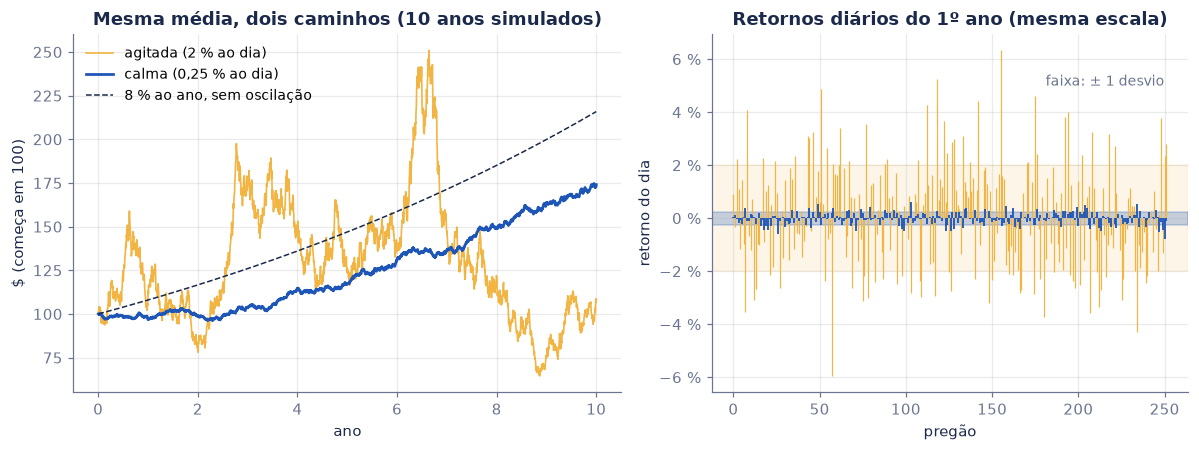

In [3]:
tab = pd.DataFrame({
    "média por dia": [calma.mean(), agitada.mean()],
    "desvio (1), ÷ n": [calma.std(), agitada.std()],
    "desvio, ÷ (n − 1)": [calma.std(ddof=1), agitada.std(ddof=1)],
    "maior alta num dia": [calma.max(), agitada.max()],
    "maior queda num dia": [calma.min(), agitada.min()],
}, index=["calma (0,25 %)", "agitada (2 %)"])
display(tab.style.format(fpc(3)))
preco_c, preco_a = 100 * np.cumprod(1 + calma), 100 * np.cumprod(1 + agitada)
print(f"$100 depois de 10 anos: calma {br(preco_c[-1])}  |  agitada {br(preco_a[-1])} (máximo no caminho: {br(preco_a.max())})  |  8 % ao ano sem oscilação: {br(100 * 1.08 ** 10)}")
assert round(preco_c[-1], 2) == 174.04 and round(preco_a[-1], 2) == 108.47

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1.15, 1]})
t = np.arange(1, dias + 1) / 252
a1.plot(t, preco_a, color=AMBER, lw=1.1, label="agitada (2 % ao dia)")
a1.plot(t, preco_c, color=BLUE, lw=1.8, label="calma (0,25 % ao dia)")
a1.plot(t, 100 * 1.08 ** t, color=NAVY, ls="--", lw=1, label="8 % ao ano, sem oscilação")
a1.set(title="Mesma média, dois caminhos (10 anos simulados)", xlabel="ano", ylabel="$ (começa em 100)"); a1.legend(frameon=False, fontsize=9)
d = np.arange(252)
a2.vlines(d, 0, agitada[:252], color=AMBER, lw=0.8)
a2.vlines(d, 0, calma[:252], color=BLUE, lw=1.2)
a2.axhspan(-agitada.std(), agitada.std(), color=AMBER, alpha=0.12)
a2.axhspan(-calma.std(), calma.std(), color=BLUE, alpha=0.25)
a2.yaxis.set_major_formatter(eixo_pc(0))
a2.set(title="Retornos diários do 1º ano (mesma escala)", xlabel="pregão", ylabel="retorno do dia")
a2.text(250, 0.05, "faixa: ± 1 desvio", ha="right", color=GREY, fontsize=9)
plt.tight_layout(); plt.show()

**Leitura.** Em dez anos, os \$100 do investimento calmo viraram \$174,04, perto dos \$215,89 que 8 % ao ano sem oscilação dariam. O agitado chegou a \$250,89 no meio do caminho e terminou em **\$108,47**. Mesma média, destinos muito diferentes: a seção 4 mostra que isso não é azar desta semente.

## 2. Do dia para o ano: a regra da raiz quadrada — eqs. (2) e (3)

A volatilidade é cotada **por ano**. Se os retornos de dias diferentes são independentes, a variância da soma é a soma das variâncias: $\mathrm{Var}(r_1 + \cdots + r_n) = n\,\sigma^2$. O desvio da soma cresce com a **raiz** do número de dias:

$$
\sigma_{\text{ano}} = \sigma_{\text{dia}}\,\sqrt{252} \tag{2}
$$

com 252 pregões por ano: $\sqrt{252} = 15{,}87$, "uns 16". O mesmo vale para qualquer prazo: a semana ($\sqrt5$), o mês ($\sqrt{21}$), dez anos ($\sqrt{2.520}$). A regra é exata para a soma de **retornos logarítmicos** independentes; para o retorno simples do ano, que é um produto, ela vale de forma aproximada (seção 3).

Se os retornos **não** são independentes, entra a autocorrelação $\rho_k$ entre dias separados por $k$ pregões:

$$
\mathrm{Var}\Big(\sum_{i=1}^{n} r_i\Big) = n\,\sigma^2\Big[1 + 2\sum_{k=1}^{n-1}\Big(1 - \frac{k}{n}\Big)\rho_k\Big] \tag{3}
$$

O colchete é a **razão de variâncias**: maior que 1 se os retornos têm inércia (um dia bom puxa outro), menor que 1 se eles revertem. Se os retornos seguem um AR(1) com $\rho_1 = 0{,}1$ (então $\rho_k = 0{,}1^k$), ele vale 1,22 em um ano, e a regra da raiz subestimaria a vol do ano em uns 10 %; com $\rho_1 = -0{,}1$, superestimaria. A seção 6 testa isso no Ibovespa.

AR(1) com ρ1 = 0,1: colchete da (3) = 1,173 (5 dias), 1,221 (252 dias); limite (1+ρ)/(1−ρ) = 1,222 -> a regra da raiz erra a vol do ano em 10,5 %
AR(1) com ρ1 = −0,1: colchete da (3) = 0,851 (5 dias), 0,819 (252 dias); limite (1+ρ)/(1−ρ) = 0,818 -> a regra da raiz erra a vol do ano em −9,5 %


simulação (4.000 anos AR(1), ρ = 0,1): Var(soma de 252)/(252·Var(dia)) = 1,242


  1 pregões: desvio simulado   2,00 %  |  2 % × √1 =   2,00 %
  5 pregões: desvio simulado   4,45 %  |  2 % × √5 =   4,47 %
 21 pregões: desvio simulado   9,18 %  |  2 % × √21 =   9,17 %
 63 pregões: desvio simulado  15,76 %  |  2 % × √63 =  15,87 %
252 pregões: desvio simulado  31,61 %  |  2 % × √252 =  31,75 %


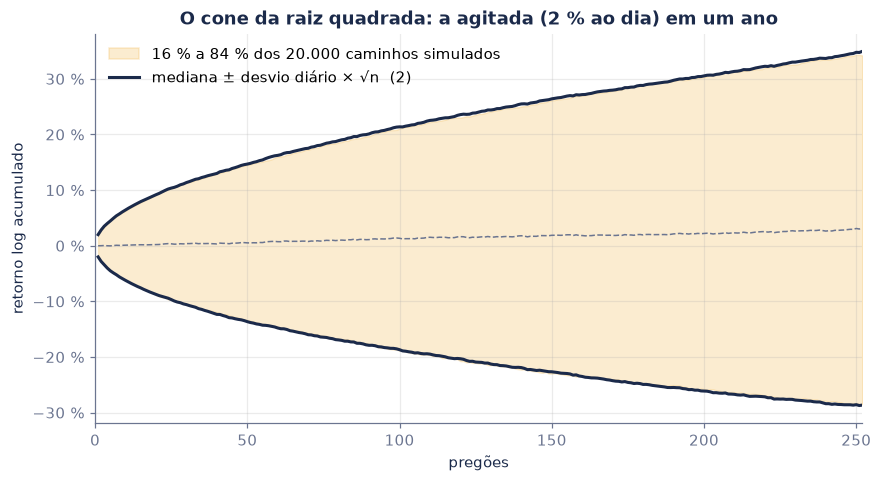

In [4]:
# (3) com autocorrelação: retornos AR(1), ρ_k = ρ^k
vr_ar1 = lambda rho_, n: 1 + 2 * sum((1 - k / n) * rho_ ** k for k in range(1, n))
for rho_ in (0.1, -0.1):
    print(f"AR(1) com ρ1 = {br(rho_, 1)}: colchete da (3) = {br(vr_ar1(rho_, 5), 3)} (5 dias), {br(vr_ar1(rho_, 252), 3)} (252 dias); limite (1+ρ)/(1−ρ) = {br((1 + rho_) / (1 - rho_), 3)}"
          f" -> a regra da raiz erra a vol do ano em {pc(math.sqrt(vr_ar1(rho_, 252)) - 1)}")
g_ar = np.random.default_rng(3)
e_ar = g_ar.standard_normal((4000, 400))
y_ar = np.zeros_like(e_ar)
for t_ in range(1, 400):
    y_ar[:, t_] = 0.1 * y_ar[:, t_ - 1] + e_ar[:, t_]
y_ar = y_ar[:, 148:]                                    # descarta o aquecimento: 252 dias estacionários
print(f"simulação (4.000 anos AR(1), ρ = 0,1): Var(soma de 252)/(252·Var(dia)) = {br(y_ar.sum(1).var() / (252 * y_ar.var()), 3)}")

rng_cone = np.random.default_rng(2026)
caminhos = np.cumsum(np.log1p(rng_cone.normal(mu, 0.02, (20000, 252))), axis=1)    # retorno log acumulado, agitada
n = np.arange(1, 253)
q16, q84 = np.percentile(caminhos, [15.87, 84.13], axis=0)
med = np.median(caminhos, axis=0)
sd_sim = caminhos.std(axis=0)
sd_log = np.log1p(rng_cone.normal(mu, 0.02, 10 ** 6)).std()
for k in (1, 5, 21, 63, 252):
    print(f"{k:>3} pregões: desvio simulado {pc(sd_sim[k - 1], 2):>8}  |  2 % × √{k} = {pc(0.02 * math.sqrt(k), 2):>8}")
assert abs(sd_sim[251] / (sd_log * math.sqrt(252)) - 1) < 0.01

fig, ax = plt.subplots()
ax.fill_between(n, q16, q84, color=AMBER, alpha=0.25, label="16 % a 84 % dos 20.000 caminhos simulados")
ax.plot(n, med + sd_log * np.sqrt(n), color=NAVY, lw=2, label="mediana ± desvio diário × √n  (2)")
ax.plot(n, med - sd_log * np.sqrt(n), color=NAVY, lw=2)
ax.plot(n, med, color=GREY, lw=1, ls="--")
ax.yaxis.set_major_formatter(eixo_pc(0))
ax.set(title="O cone da raiz quadrada: a agitada (2 % ao dia) em um ano", xlabel="pregões", ylabel="retorno log acumulado", xlim=(0, 252))
ax.legend(frameon=False, loc="upper left"); plt.show()

**Leitura.** O desvio do retorno acumulado cresce exatamente como $\sqrt n$: 2 % em um dia, 4,45 % em uma semana, 9,18 % em um mês, 31,61 % em um ano. Por isso o cone abre rápido no começo e devagar depois: dobrar o prazo multiplica a incerteza por 1,41, não por 2. (Em 252 pregões, 31,61 % e não 31,75 % porque o cone usa o log do retorno, cujo desvio é um pouco menor que o do retorno simples.)

## 3. "2 em 3": a curva de sino — eq. (4)

Se o retorno do ano fosse normal, com média $\mu$ e desvio $\sigma$, cairia dentro de $\mu \pm \sigma$ com probabilidade

$$
P(\mu - \sigma < X < \mu + \sigma) = 2\,\Phi(1) - 1 \approx 68{,}3\,\% \tag{4}
$$

com $\Phi$ a normal acumulada. É o "uns dois anos a cada três" do vídeo. Mas a simulação dá **64,1 %** (calma) e **65,8 %** (agitada), não 68,3 %. Duas razões:

1. **O retorno do ano é um produto, não uma soma.** $1 + R = \prod (1 + r_i)$. O desvio exato de $R$ é $(1+\mu_a)\sqrt{\big(1 + s^2/(1+\mu)^2\big)^{252} - 1}$, um pouco **maior** que $s\sqrt{252}$ (a nota técnica demonstra). A faixa de $\pm$ vol fica mais estreita que $\pm 1$ desvio de verdade, e pega menos anos.
2. **A faixa usa a vol estimada em 10 anos** ($3{,}93\,\%$ e $31{,}59\,\%$ do `vol.py`), não a verdadeira ($3{,}97\,\%$ e $31{,}75\,\%$).

Para a agitada há ainda a **assimetria**: o produto de muitos $(1+r_i)$ é aproximadamente **lognormal**, com cauda longa à direita (anos de +100 %) e a esquerda presa em −100 %.

,vol s√252,vol estimada (tela),desvio exato do ano,desvio dos 100.000 anos,normal (4),"lognormal, banda = vol estimada",simulação (tela)
,,,,,,,
calma,"3,97 %","3,93 %","4,29 %","4,27 %","68,3 %","64,1 %","64,1 %"
agitada,"31,75 %","31,59 %","35,16 %","35,13 %","68,3 %","65,7 %","65,8 %"


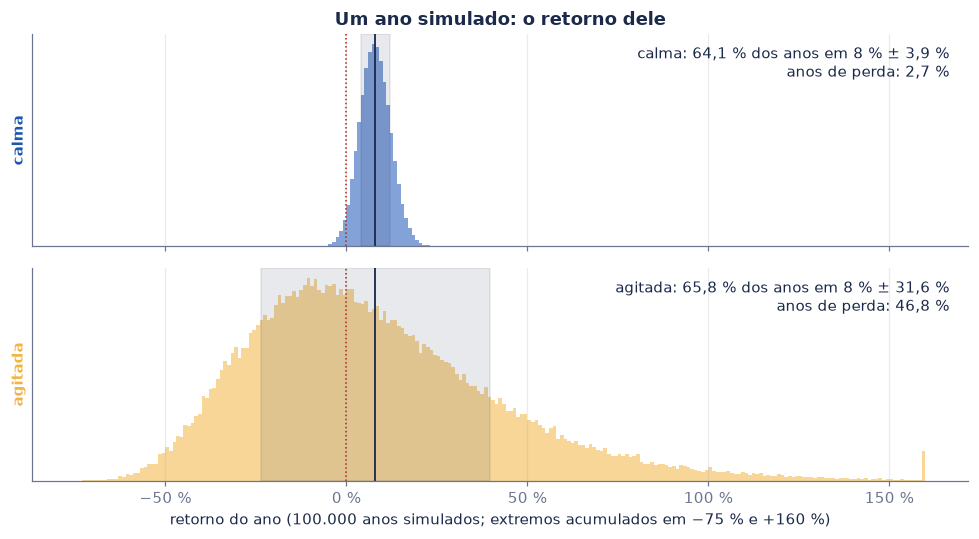

In [5]:
def sd_exato(s, m=mu, n=252):
    # desvio-padrão exato do retorno simples de n dias com retornos diários iid de média m e desvio s
    return (1 + m) ** n * math.sqrt((1 + s ** 2 / (1 + m) ** 2) ** n - 1)

def dentro_lognormal(s, banda, n=252):
    # P(8 % − banda < R < 8 % + banda) com ln(1 + R) ~ normal (aproximação lognormal)
    m_log, s_log = n * (math.log(1 + mu) - s ** 2 / (2 * (1 + mu) ** 2)), s / (1 + mu) * math.sqrt(n)
    lo, hi = math.log(1.08 - banda), math.log(1.08 + banda)
    return Phi((hi - m_log) / s_log) - Phi((lo - m_log) / s_log)

linhas = []
for s, nome, v_est in ((0.0025, "calma", vc), (0.02, "agitada", va)):
    linhas.append({"": nome, "vol s√252": s * math.sqrt(252), "vol estimada (tela)": v_est, "desvio exato do ano": sd_exato(s),
                   "desvio dos 100.000 anos": ano[nome].std(), "normal (4)": 2 * Phi(1) - 1,
                   "lognormal, banda = vol estimada": dentro_lognormal(s, v_est), "simulação (tela)": dentro[nome]})
tab3 = pd.DataFrame(linhas).set_index("")
display(tab3.style.format({c: fpc(2 if i < 4 else 1) for i, c in enumerate(tab3.columns)}))
assert abs(tab3.loc["calma", "desvio exato do ano"] / ano["calma"].std() - 1) < 0.01
assert abs(tab3.loc["agitada", "desvio exato do ano"] / ano["agitada"].std() - 1) < 0.01
assert all(abs(tab3["lognormal, banda = vol estimada"] - tab3["simulação (tela)"]) < 0.005)

fig, axs = plt.subplots(2, 1, figsize=(9, 5.0), sharex=True)
for ax, nome, vol, cor in ((axs[0], "calma", vc, BLUE), (axs[1], "agitada", va, AMBER)):
    v = ano[nome]
    ax.hist(np.clip(v, -0.75, 1.6), bins=np.linspace(-0.75, 1.6, 236), color=cor, alpha=0.55)
    ax.axvspan(0.08 - vol, 0.08 + vol, color=NAVY, alpha=0.10)
    ax.axvline(0.08, color=NAVY, lw=1.2); ax.axvline(0, color=RED, lw=1, ls=":")
    ax.text(0.98, 0.8, f"{nome}: {pc(dentro[nome])} dos anos em 8 % ± {pc(vol)}\nanos de perda: {pc(perda[nome])}", transform=ax.transAxes, ha="right", color=NAVY, fontsize=10)
    ax.set(yticks=[]); ax.set_ylabel(nome, color=cor, weight="bold")
axs[1].xaxis.set_major_formatter(eixo_pc(0)); axs[1].set_xlabel("retorno do ano (100.000 anos simulados; extremos acumulados em −75 % e +160 %)")
axs[0].set_title("Um ano simulado: o retorno dele"); plt.tight_layout(); plt.show()

**Leitura.** O desvio exato do retorno do ano (4,29 % e 35,16 %) bate com o dos 100.000 anos simulados (4,27 % e 35,13 %) e é maior que a vol $s\sqrt{252}$. Com a faixa da tela (8 % ± a vol estimada), a aproximação lognormal dá 64,1 % e 65,7 %, contra 64,1 % e 65,8 % da simulação. O "2 em 3" do vídeo está certo como ordem de grandeza; os 68,3 % da curva de sino são o teto, e só valem para uma soma de retornos com a vol verdadeira.

## 4. Anos de perda: por que 46,8 % e não 40 % — eq. (5)

A conta ingênua trata o retorno do ano como normal com média 8 % e desvio igual à vol: $P(R < 0) = \Phi(-0{,}08/\sigma)$. Para a agitada, $\Phi(-0{,}08/0{,}316) \approx 40\,\%$. A simulação dá **46,8 %**. O que falta é a **mediana**.

Com retornos compostos, o que se soma é o log: $\ln(1+R) = \sum_i \ln(1+r_i)$. Pela regra da raiz e pelo teorema central do limite, $\ln(1+R)$ é aproximadamente normal, com desvio $\sigma \approx s\sqrt{252}$ e média $\ln(1+\mu_a) - \sigma^2/2$. Perder dinheiro é $\ln(1+R) < 0$:

$$
P(\text{ano de perda}) \approx \Phi\!\left(-\,\frac{\ln(1+\mu_a) - \sigma^2/2}{\sigma}\right) \tag{5}
$$

O termo $-\sigma^2/2$ é o **arrasto da volatilidade**: com a **mesma média** de 8 %, quanto maior a vol, menor o retorno **mediano**. Para a agitada, $\ln 1{,}08 - 0{,}317^2/2 = 0{,}027$: pela (5), o ano mediano rende só **2,7 %** (2,5 % nos 100.000 anos simulados, dentro do erro amostral). A média de 8 % é puxada por poucos anos enormes; metade dos anos fica abaixo de uns 2,7 %, e quase metade abaixo de zero.

,vol σ,ingênua Φ(−μ/σ),lognormal (5),simulação (tela),média dos anos,mediana dos anos,mediana por (5)
,,,,,,,
calma,"3,97 %","2,19 %","2,74 %","2,74 %","7,97 %","7,88 %","7,92 %"
agitada,"31,74 %","40,05 %","46,66 %","46,84 %","7,90 %","2,52 %","2,69 %"


mediana da agitada: simulação 2,52 % ± 0,14 p.p. (erro-padrão); (5): 2,69 %
calma: m = ln 1,08 − σ²/2 = 0,0762, m/σ = 1,920
agitada: m = ln 1,08 − σ²/2 = 0,0266, m/σ = 0,084
perda acumulada em  1 ano : calma  2,7430 %  |  agitada  46,7 %
perda acumulada em  5 anos: calma  0,0009 %  |  agitada  42,6 %
perda acumulada em 10 anos: calma  0,0000 %  |  agitada  39,6 %
perda acumulada em 30 anos: calma  0,0000 %  |  agitada  32,3 %


vol   5 %: simulação 6,7 %  |  (5) 6,5 %  |  ingênua 5,5 %
vol  10 %: simulação 24,1 %  |  (5) 23,6 %  |  ingênua 21,2 %
vol  15 %: simulação 32,6 %  |  (5) 33,1 %  |  ingênua 29,7 %
vol  20 %: simulação 38,0 %  |  (5) 38,8 %  |  ingênua 34,5 %
vol  25 %: simulação 43,1 %  |  (5) 42,7 %  |  ingênua 37,4 %
vol  40 %: simulação 50,4 %  |  (5) 50,3 %  |  ingênua 42,1 %


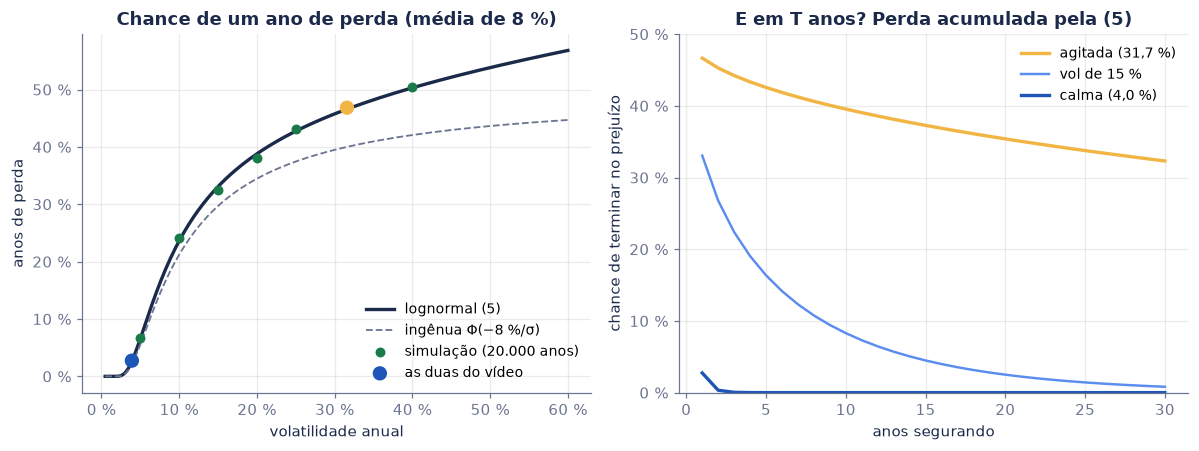

In [6]:
def p_perda(sig, mu_a=0.08, T=1):
    # (5) para um horizonte de T anos: ln(1+R_T) ~ N(T(ln(1+mu_a) − σ²/2), σ²T)
    return Phi(-(math.log(1 + mu_a) - sig ** 2 / 2) * T / (sig * math.sqrt(T)))

linhas = []
for s, nome in ((0.0025, "calma"), (0.02, "agitada")):
    sig = s / (1 + mu) * math.sqrt(252)
    linhas.append({"": nome, "vol σ": sig, "ingênua Φ(−μ/σ)": Phi(-0.08 / sig), "lognormal (5)": p_perda(sig), "simulação (tela)": perda[nome],
                   "média dos anos": ano[nome].mean(), "mediana dos anos": float(np.median(ano[nome])), "mediana por (5)": math.exp(math.log(1.08) - sig ** 2 / 2) - 1})
tab4 = pd.DataFrame(linhas).set_index("")
display(tab4.style.format(fpc(2)))
assert all(abs(tab4["lognormal (5)"] - tab4["simulação (tela)"]) < 0.003)
assert round(100 * tab4.loc["agitada", "ingênua Φ(−μ/σ)"]) == 40
assert round(100 * tab4.loc["agitada", "mediana por (5)"], 1) == 2.7 and round(100 * tab4.loc["agitada", "mediana dos anos"], 1) == 2.5
ep_mediana = 1.2533 * ano["agitada"].std() / math.sqrt(100000)            # erro-padrão da mediana amostral
print(f"mediana da agitada: simulação {pc(tab4.loc['agitada', 'mediana dos anos'], 2)} ± {br(100 * ep_mediana, 2)} p.p. (erro-padrão); (5): {pc(tab4.loc['agitada', 'mediana por (5)'], 2)}")

# horizonte: perder dinheiro em T anos
for s, nome in ((0.0025, "calma"), (0.02, "agitada")):
    sig = s / (1 + mu) * math.sqrt(252)
    m_ = math.log(1.08) - sig ** 2 / 2
    print(f"{nome}: m = ln 1,08 − σ²/2 = {br(m_, 4)}, m/σ = {br(m_ / sig, 3)}")
for T in (1, 5, 10, 30):
    print(f"perda acumulada em {T:>2} {'ano ' if T == 1 else 'anos'}: calma {pc(p_perda(0.0025 / (1 + mu) * math.sqrt(252), T=T), 4):>9}  |  agitada {pc(p_perda(0.02 / (1 + mu) * math.sqrt(252), T=T)):>7}")

# conferir (5) com simulação em outras vols (20.000 anos cada, outra semente)
rng_p = np.random.default_rng(5)
grade = [0.05, 0.10, 0.15, 0.20, 0.25, 0.40]
sim_p = [float(((1 + rng_p.normal(mu, v / math.sqrt(252), (20000, 252))).prod(1) < 1).mean()) for v in grade]
for v, p in zip(grade, sim_p):
    print(f"vol {pc(v, 0):>5}: simulação {pc(p)}  |  (5) {pc(p_perda(v))}  |  ingênua {pc(Phi(-0.08 / v))}")
    assert abs(p - p_perda(v)) < 0.012

sg = np.linspace(0.005, 0.6, 200)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.2))
a1.plot(sg, [p_perda(v) for v in sg], color=NAVY, lw=2.2, label="lognormal (5)")
a1.plot(sg, [Phi(-0.08 / v) for v in sg], color=GREY, lw=1.2, ls="--", label="ingênua Φ(−8 %/σ)")
a1.scatter(grade, sim_p, color=GREEN, zorder=3, s=30, label="simulação (20.000 anos)")
a1.scatter([vc, va], [perda["calma"], perda["agitada"]], color=[BLUE, AMBER], zorder=4, s=70, label="as duas do vídeo")
a1.xaxis.set_major_formatter(eixo_pc(0)); a1.yaxis.set_major_formatter(eixo_pc(0))
a1.set(title="Chance de um ano de perda (média de 8 %)", xlabel="volatilidade anual", ylabel="anos de perda"); a1.legend(frameon=False, fontsize=9)
Ts = np.arange(1, 31)
a2.plot(Ts, [p_perda(0.02 / (1 + mu) * math.sqrt(252), T=T) for T in Ts], color=AMBER, lw=2.2, label="agitada (31,7 %)")
a2.plot(Ts, [p_perda(0.15, T=T) for T in Ts], color=LIGHT, lw=1.6, label="vol de 15 %")
a2.plot(Ts, [p_perda(0.0025 / (1 + mu) * math.sqrt(252), T=T) for T in Ts], color=BLUE, lw=2.2, label="calma (4,0 %)")
a2.yaxis.set_major_formatter(eixo_pc(0))
a2.set(title="E em T anos? Perda acumulada pela (5)", xlabel="anos segurando", ylabel="chance de terminar no prejuízo", ylim=(0, 0.5)); a2.legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.show()

**Leitura.** A (5) acerta a simulação em todas as vols testadas (diferença máxima de 1 ponto percentual), e a conta ingênua erra sempre para menos: com vol de 25 %, ela diz 37 % de anos de perda quando são 43 %. O motivo é a mediana: com a mesma média de 8 %, a agitada tem ano mediano de 2,7 %.

Esperar não resolve tudo. A chance de prejuízo em $T$ anos é $\Phi(-m\sqrt T/\sigma)$, com $m = \ln(1+\mu_a) - \sigma^2/2$: ela cai com $\sqrt T$, e cai devagar quando $m$ é pequeno. A calma praticamente nunca perde em 5 anos. A agitada ainda termina no prejuízo em **39,6 % das décadas** e em **32,3 % dos períodos de 30 anos**. Mesma média, e a vol come quase todo o crescimento típico: é o arrasto da volatilidade.

## 5. Quanto dado é preciso para saber a vol — eq. (6)

A volatilidade da tela é uma **estimativa**: 10 anos de dados deram 3,93 % e 31,59 %, contra 3,97 % e 31,75 % verdadeiros. Quão longe ela pode cair? Para retornos independentes com curtose $\kappa$ (3 na normal), o erro-padrão do desvio estimado com $n$ dias é

$$
\frac{\mathrm{EP}(\hat\sigma)}{\sigma} \approx \sqrt{\frac{\kappa - 1}{4n}} \qquad\Big(= \frac{1}{\sqrt{2n}}\ \text{na normal}\Big) \tag{6}
$$

Para saber a vol com **±10 %** (95 % de confiança), é preciso $1{,}96 \times \mathrm{EP} \le 10\,\%$, isto é, $n \ge 96\,(\kappa - 1)$: **192 pregões** na normal. Com caudas grossas, muito mais.

E a **média**? O erro-padrão da média anual estimada com $T$ anos é $\sigma/\sqrt{T}$, **não importa quantos dias** você tenha dentro de cada ano. Para a agitada, com 10 anos: $31{,}7\,\%/\sqrt{10} = 10\,\%$ ao ano de erro-padrão numa média de 8 %. Medir a vol é fácil; medir a média é quase impossível (Merton, 1980).

In [7]:
rng_ep = np.random.default_rng(11)
linhas = []
for n_ in (21, 63, 252, 2520):
    z_n = rng_ep.standard_normal((20000, n_))
    z_t = rng_ep.standard_t(5, (20000, n_)) / math.sqrt(5 / 3)          # t de Student com 5 graus: curtose 9
    linhas.append({"pregões": n_, "normal: simulado": z_n.std(axis=1).std(), "normal: (6)": math.sqrt(2 / (4 * n_)),
                   "t5 (κ = 9): simulado": z_t.std(axis=1).std(), "t5: (6)": math.sqrt(8 / (4 * n_))})
tep = pd.DataFrame(linhas)
display(tep.style.format({"pregões": lambda v: br(v, 0), **{c: fpc(1) for c in tep.columns[1:]}}).hide(axis="index"))
dias_10 = lambda kappa: 1.96 ** 2 * (kappa - 1) / (4 * 0.10 ** 2)
print(f"pregões para ±10 % (95 %): normal {br(dias_10(3), 0)}  |  t5 {br(dias_10(9), 0)}")

# a média, no próprio vol.py: 10 anos de dados
media_c, media_a = 252 * calma.mean(), 252 * agitada.mean()
print(f"média anual estimada com os 10 anos da tela: calma {pc(media_c)}  |  agitada {pc(media_a)}  (verdadeira: {pc(252 * mu, 2)})")
print(f"erro-padrão da média em 10 anos: calma {pc(vc / math.sqrt(10))}  |  agitada {pc(va / math.sqrt(10))}")
print(f"erro da vol estimada em 10 anos: calma {pc(vc / (0.0025 * math.sqrt(252)) - 1)}  |  agitada {pc(va / (0.02 * math.sqrt(252)) - 1)}")
assert round(dias_10(3)) == 192

pregões,normal: simulado,normal: (6),t5 (κ = 9): simulado,t5: (6)
21,"15,4 %","15,4 %","23,7 %","30,9 %"
63,"8,9 %","8,9 %","15,0 %","17,8 %"
252,"4,5 %","4,5 %","8,0 %","8,9 %"
2.520,"1,4 %","1,4 %","2,7 %","2,8 %"


pregões para ±10 % (95 %): normal 192  |  t5 768
média anual estimada com os 10 anos da tela: calma 5,6 %  |  agitada 5,8 %  (verdadeira: 7,70 %)
erro-padrão da média em 10 anos: calma 1,2 %  |  agitada 10,0 %
erro da vol estimada em 10 anos: calma −1,0 %  |  agitada −0,5 %


**Leitura.** A (6) acerta na normal com qualquer $n$; com caudas grossas (t de Student, curtose 9), o erro dobra e é preciso **768 pregões** para os mesmos ±10 %. Nos 10 anos do `vol.py`, a vol saiu com erro de −1,0 % e −0,5 %. A média anual, com os mesmos dados, saiu **5,6 % e 5,8 %**, contra 7,7 % verdadeiros ($252\,\mu$). Para a agitada, o erro-padrão da média em 10 anos é de 10 pontos ao ano: o intervalo de 95 % iria de uns −12 % a +28 %. A volatilidade se aprende com dados diários; a média, só com décadas.

## 6. Dado real: o Ibovespa desde 1995

Agora com dado de verdade: o fechamento diário do Ibovespa de 02/01/1995 a 16/10/2026 (`dados/ibovespa.csv`, Yahoo Finance). Começamos em 1995 para deixar de fora a hiperinflação e a troca de moeda. Antes de qualquer conta, conferimos datas repetidas e os maiores movimentos (um salto absurdo seria erro de dado).

In [8]:
ibov = pd.read_csv("dados/ibovespa.csv", parse_dates=["data"]).set_index("data")["ibov"]
r_ib = np.log(ibov).diff().dropna()                   # retorno log diário
x = r_ib.values
print(f"{len(ibov)} fechamentos de {ibov.index[0]:%d/%m/%Y} a {ibov.index[-1]:%d/%m/%Y}; datas repetidas: {ibov.index.duplicated().sum()}; pregões por ano: {br(len(x) / ((ibov.index[-1] - ibov.index[0]).days / 365.25), 1)}")
maiores = r_ib.abs().sort_values(ascending=False).head(6)
print("os seis maiores movimentos (retorno simples):", "; ".join(f"{d:%d/%m/%Y} {pc(math.expm1(r_ib[d]))}" for d in maiores.index))
vol_d = x.std()
kurt = ((x - x.mean()) ** 4).mean() / x.var() ** 2
print(f"desvio diário {pc(vol_d, 2)} -> vol anual pela (2): {pc(vol_d * math.sqrt(252))}  |  curtose {br(kurt, 1)} (normal: 3)")
pregoes_ano = len(x) / ((ibov.index[-1] - ibov.index[0]).days / 365.25)
print(f"anualizar com 252 e não com os {br(pregoes_ano, 1)} pregões observados por ano aumenta a vol em {pc(math.sqrt(252 / pregoes_ano) - 1)}")
assert ibov.index.is_monotonic_increasing and not ibov.index.duplicated().any()
assert round(100 * vol_d * math.sqrt(252), 1) == 31.1 and round(kurt, 1) == 18.4

7875 fechamentos de 02/01/1995 a 16/10/2026; datas repetidas: 0; pregões por ano: 247,7
os seis maiores movimentos (retorno simples): 15/01/1999 33,4 %; 10/03/1995 25,6 %; 10/09/1998 −15,8 %; 15/09/1998 18,7 %; 27/10/1997 −15,0 %; 12/03/2020 −14,8 %
desvio diário 1,96 % -> vol anual pela (2): 31,1 %  |  curtose 18,4 (normal: 3)
anualizar com 252 e não com os 247,7 pregões observados por ano aumenta a vol em 0,9 %


Os maiores dias são todos reais: 15/01/1999 (+33 %, o dia seguinte à desvalorização do real), setembro de 1998 (moratória da Rússia), 27/10/1997 (crise asiática), março de 1995 (crise do México) e março de 2020 (covid).

### 6.1 A vol ano a ano

O vídeo trata a vol como um número fixo. No Ibovespa, ela vai de menos de 13 % a mais de 57 % ao ano. A linha é a vol de cada dia pela EWMA (seção 7); as barras, o desvio de cada ano civil pela (2).

os cinco anos mais agitados: 1998 57,5 %; 1995 57,1 %; 2008 52,3 %; 1997 47,1 %; 1999 46,6 %
os três mais calmos: 2024 12,9 %; 2025 15,2 %; 2023 17,3 %
vol EWMA (λ = 0,94) em 16/10/2026: 27,4 % ao ano = 1,73 % ao dia


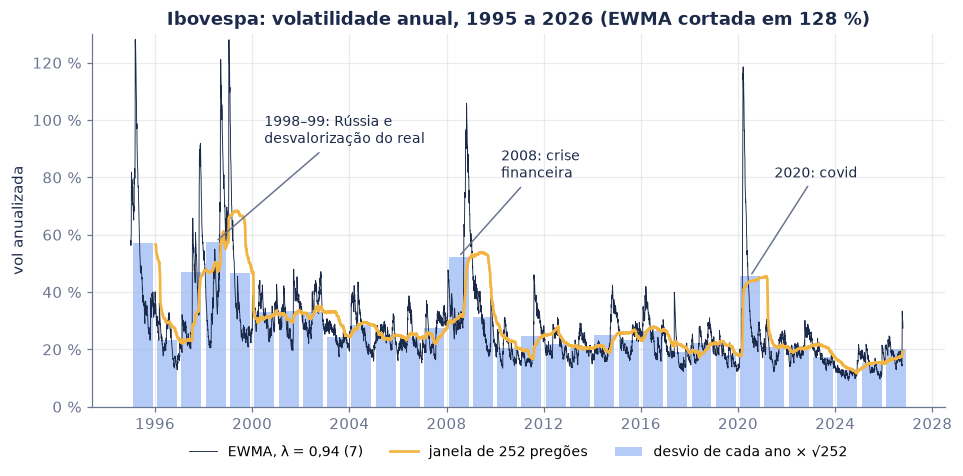

In [9]:
vol_ano = r_ib.groupby(r_ib.index.year).std() * math.sqrt(252)
ret_ano = ibov.groupby(ibov.index.year).last().pct_change()
ret_ano.iloc[0] = ibov[ibov.index.year == 1995].iloc[-1] / ibov.iloc[0] - 1
anos_ib = pd.DataFrame({"retorno": ret_ano, "vol (2)": vol_ano})
print("os cinco anos mais agitados:", "; ".join(f"{a} {pc(v)}" for a, v in vol_ano.sort_values(ascending=False).head(5).items()))
print("os três mais calmos:", "; ".join(f"{a} {pc(v)}" for a, v in vol_ano.sort_values().head(3).items()))

def ewma_var(r2, lam, s0):
    # (7): s[t] = previsão da variância do dia t feita no fim do dia t−1
    s = np.empty(len(r2) + 1); s[0] = s0
    for t in range(len(r2)):
        s[t + 1] = lam * s[t] + (1 - lam) * r2[t]
    return s

ew = ewma_var(x ** 2, 0.94, (x[:252] ** 2).mean())
vol_ew = pd.Series(np.sqrt(252 * ew[1:]), index=r_ib.index)            # vol do dia seguinte, sabida no fim de cada dia
vol_252 = np.sqrt(252 * (r_ib ** 2).rolling(252).mean())
print(f"vol EWMA (λ = 0,94) em {r_ib.index[-1]:%d/%m/%Y}: {pc(vol_ew.iloc[-1])} ao ano = {pc(vol_ew.iloc[-1] / math.sqrt(252), 2)} ao dia")

fig, ax = plt.subplots(figsize=(10, 4.4))
anos_x =pd.to_datetime([f"{a}-07-01" for a in vol_ano.index])
ax.bar(anos_x, vol_ano.values, width=300, color=LIGHT, alpha=0.45, label="desvio de cada ano × √252")
ax.plot(vol_ew.index, vol_ew.clip(upper=1.28).values, color=NAVY, lw=0.6, label="EWMA, λ = 0,94 (7)")
ax.plot(vol_252.index, vol_252.values, color=AMBER, lw=1.8, label="janela de 252 pregões")
for a, txt, xt, yt in ((1998, "1998–99: Rússia e\ndesvalorização do real", 2000.6, 0.92), (2008, "2008: crise\nfinanceira", 2010.3, 0.80), (2020, "2020: covid", 2021.6, 0.80)):
    ax.annotate(txt, (pd.Timestamp(f"{a}-07-01"), vol_ano[a]), (pd.Timestamp(f"{int(xt)}-{int(1 + 11 * (xt % 1)):02d}-01"), yt), color=NAVY, fontsize=9, arrowprops=dict(arrowstyle="-", color=GREY))
ax.yaxis.set_major_formatter(eixo_pc(0)); ax.set_ylim(0, 1.3)
ax.set(title="Ibovespa: volatilidade anual, 1995 a 2026 (EWMA cortada em 128 %)", ylabel="vol anualizada")
ax.legend(frameon=False, fontsize=9, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.07)); plt.show()

### 6.2 O "2 em 3" e os anos de perda valem no Ibovespa?

Com os retornos anuais de 1995 a 2025 (31 anos civis completos): quantos ficaram dentro de média ± 1 desvio, e quantos foram de perda, contra o que a (4) e a (5) prevêem com a média e a vol do próprio Ibovespa?

In [10]:
ra = anos_ib.loc[1995:2025, "retorno"]
m_a, s_a = ra.mean(), ra.std()
dentro_ib = int(((ra > m_a - s_a) & (ra < m_a + s_a)).sum())
perdas_ib = int((ra < 0).sum())
lr = np.log1p(ra)
p5_ib = Phi(-lr.mean() / lr.std())                  # (5) com a média e o desvio do log anual
vol_diaria_95_25 = r_ib[: "2025"].std() * math.sqrt(252)
print(f"retorno anual médio {pc(m_a)}, desvio {pc(s_a)}; mediana {pc(ra.median())}; média do log {pc(lr.mean())}, desvio do log {pc(lr.std())}")
print(f"dentro de média ± 1 desvio: {dentro_ib} de {len(ra)} = {pc(dentro_ib / len(ra))}   (normal (4): 68,3 %)")
print(f"anos de perda: {perdas_ib} de {len(ra)} = {pc(perdas_ib / len(ra))}   (lognormal (5): {pc(p5_ib)})")
print(f"vol dos dados diários (2), mesmos anos: {pc(vol_diaria_95_25)}  ×  desvio do log anual: {pc(lr.std())}")
print("anos fora da faixa:", ", ".join(f"{a} ({pc(v, 0)})" for a, v in ra[(ra <= m_a - s_a) | (ra >= m_a + s_a)].items()))
assert len(ra) == 31 and dentro_ib == 25 and perdas_ib == 12

retorno anual médio 18,1 %, desvio 40,4 %; mediana 7,4 %; média do log 11,7 %, desvio do log 31,4 %
dentro de média ± 1 desvio: 25 de 31 = 80,6 %   (normal (4): 68,3 %)
anos de perda: 12 de 31 = 38,7 %   (lognormal (5): 35,5 %)
vol dos dados diários (2), mesmos anos: 31,3 %  ×  desvio do log anual: 31,4 %
anos fora da faixa: 1996 (64 %), 1998 (−33 %), 1999 (152 %), 2003 (97 %), 2008 (−41 %), 2009 (83 %)


**Leitura.** O "2 em 3" **não** vale assim no Ibovespa: 25 dos 31 anos (80,6 %) caíram dentro de média ± 1 desvio. Não é que a bolsa seja mais calma do que parece; é que três anos enormes (1999: +152 %, 2003: +97 %, 2009: +83 %) inflam o desvio anual para 40,4 % e alargam a faixa. É a cauda grossa vista de outro ângulo: muitos anos perto do meio, poucos muito longe. Já os anos de perda batem razoavelmente: 12 de 31 (38,7 %), contra 35,5 % pela (5). E a mediana (7,4 %) fica bem abaixo da média (18,1 %), como na agitada do vídeo.

### 6.3 A regra da raiz quadrada vale no Ibovespa?

Pela eq. (3), se a vol anualizada a partir de retornos de 1 dia, de 1 semana, de 1 mês e de 1 ano der o mesmo número, os retornos não têm memória e a (2) vale. A medida é a **razão de variâncias** de Lo e MacKinlay (1988), o colchete da (3) estimado com somas sobrepostas de $q$ pregões:

$$
VR(q) = \frac{\mathrm{Var}(r_{t} + \cdots + r_{t+q-1})}{q\,\mathrm{Var}(r_t)}, \qquad \sigma_{q,\text{anual}} = \sigma_{\text{dia}}\sqrt{252\,VR(q)}
$$

Os dias não são independentes (a vol se agrupa), então o intervalo de confiança vem de um **bootstrap em blocos** circulares de 252 pregões: sorteamos anos inteiros de dados, com a estrutura de dependência de dentro do bloco preservada.

prazo,q,VR(q),IC 95 % (blocos),vol anual,vol: IC 95 %
1 dia,1,"1,000",,"31,1 %",
1 semana,5,"0,956","0,91 a 1,00","30,4 %","29,7 % a 31,2 %"
1 mês,21,"0,931","0,84 a 1,04","30,0 %","28,6 % a 31,7 %"
1 trimestre,63,"0,873","0,75 a 1,07","29,1 %","26,9 % a 32,1 %"
1 ano,252,"0,741","0,50 a 1,08","26,8 %","22,0 % a 32,4 %"


1995–2002: ρ1 = 0,055  VR(5) = 1,013  VR(21) = 0,950  VR(63) = 0,813
2003–2014: ρ1 = −0,010  VR(5) = 0,904  VR(21) = 0,831  VR(63) = 0,916
2015–2026: ρ1 = −0,088  VR(5) = 0,906  VR(21) = 1,046  VR(63) = 0,968


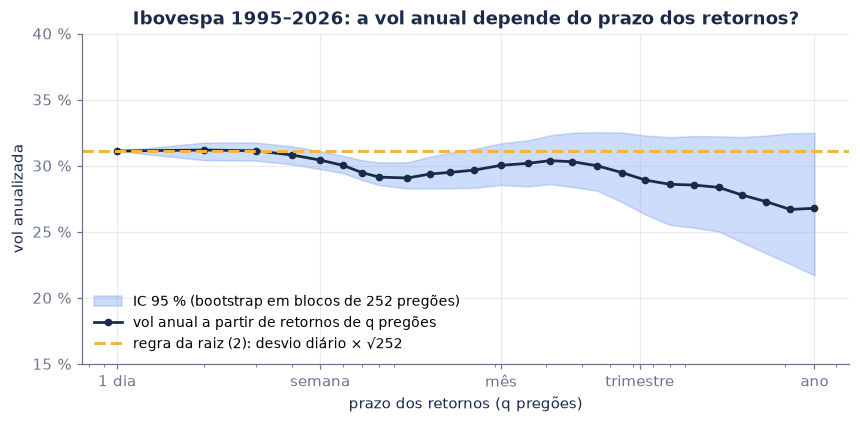

In [11]:
def blocos(n, L, B, seed):
    # índices de B reamostras por bootstrap em blocos circulares de tamanho L
    g = np.random.default_rng(seed)
    ini = g.integers(0, n, size=(B, -(-n // L)))
    return ((ini[:, :, None] + np.arange(L)) % n).reshape(B, -1)[:, :n]

def vr(y, q):
    c = np.concatenate([[0.0], np.cumsum(y - y.mean())])
    return (c[q:] - c[:-q]).var() / (q * y.var())

IDX = blocos(len(x), 252, 1000, seed=1)
linhas = []
for q, nome in ((1, "1 dia"), (5, "1 semana"), (21, "1 mês"), (63, "1 trimestre"), (252, "1 ano")):
    v = vr(x, q) if q > 1 else 1.0
    bs = np.array([vr(x[i], q) for i in IDX]) if q > 1 else np.ones(1)
    lo, hi = np.percentile(bs, [2.5, 97.5])
    linhas.append({"prazo": nome, "q": q, "VR(q)": v, "IC 95 % (blocos)": f"{br(lo, 2)} a {br(hi, 2)}" if q > 1 else "",
                   "vol anual": vol_d * math.sqrt(252 * v), "vol: IC 95 %": f"{pc(vol_d * math.sqrt(252 * lo))} a {pc(vol_d * math.sqrt(252 * hi))}" if q > 1 else ""})
tvr = pd.DataFrame(linhas)
display(tvr.style.format({"VR(q)": lambda v: br(v, 3), "vol anual": fpc(1)}).hide(axis="index"))
assert [round(v, 3) for v in tvr["VR(q)"]] == [1.0, 0.956, 0.931, 0.873, 0.741]
rho = lambda y, k: float(np.corrcoef(y[k:], y[:-k])[0, 1])
for a, b in (("1995", "2002"), ("2003", "2014"), ("2015", "2026")):
    y = r_ib[a:b].values
    print(f"{a}–{b}: ρ1 = {br(rho(y, 1), 3)}  VR(5) = {br(vr(y, 5), 3)}  VR(21) = {br(vr(y, 21), 3)}  VR(63) = {br(vr(y, 63), 3)}")

qs = np.unique(np.round(np.geomspace(1, 252, 30)).astype(int))
vrs = np.array([vr(x, q) for q in qs])
bsq = np.array([[vr(x[i], q) for q in qs] for i in IDX[:300]])
fig, ax = plt.subplots(figsize=(9, 3.9))
ax.fill_between(qs, vol_d * np.sqrt(252 * np.percentile(bsq, 2.5, axis=0)), vol_d * np.sqrt(252 * np.percentile(bsq, 97.5, axis=0)), color=LIGHT, alpha=0.3, label="IC 95 % (bootstrap em blocos de 252 pregões)")
ax.plot(qs, vol_d * np.sqrt(252 * vrs), "o-", color=NAVY, ms=4, lw=1.8, label="vol anual a partir de retornos de q pregões")
ax.axhline(vol_d * math.sqrt(252), color=AMBER, lw=2, ls="--", label="regra da raiz (2): desvio diário × √252")
ax.set_xscale("log"); ax.set_xticks([1, 5, 21, 63, 252]); ax.set_xticklabels(["1 dia", "semana", "mês", "trimestre", "ano"])
ax.yaxis.set_major_formatter(eixo_pc(0)); ax.set_ylim(0.15, 0.40)
ax.set(title="Ibovespa 1995–2026: a vol anual depende do prazo dos retornos?", xlabel="prazo dos retornos (q pregões)", ylabel="vol anualizada")
ax.legend(frameon=False, fontsize=9, loc="lower left"); plt.show()

**Leitura.** Todas as razões de variâncias ficam **abaixo de 1**: a vol anual medida com retornos de uma semana (30,4 %), de um mês (30,0 %), de um trimestre (29,1 %) e de um ano (26,8 %) é menor que a da regra da raiz sobre os retornos diários (31,1 %). É sinal de **reversão**: parte dos movimentos de um dia se desfaz nos dias seguintes. Mas nenhum intervalo de 95 % exclui o 1 (o da semana encosta nele, de 0,91 a 1,00). Conclusão honesta: no Ibovespa, a regra da raiz é uma boa aproximação e, se erra, erra para cima.

Os subperíodos contam a história da liquidez: em 1995–2002, $\rho_1 = +0{,}055$ (preços "velhos" de ações pouco negociadas, que só se ajustam no dia seguinte); em 2015–2026, $\rho_1 = -0{,}088$, puxado pelas reversões de 2020 e 2021.

### 6.4 Quão bem conhecemos a vol do Ibovespa?

A (6) supõe dias independentes. No Ibovespa, os $r^2$ têm memória longa (seção 7), e o bootstrap em blocos mede o erro de verdade.

In [12]:
linhas = [{"método": "normal: 1/√(2n)", "erro-padrão relativo": 1 / math.sqrt(2 * len(x))},
          {"método": f"(6) com a curtose observada ({br(kurt, 1)})", "erro-padrão relativo": math.sqrt((kurt - 1) / (4 * len(x)))}]
for L in (21, 63, 252):
    bs = np.array([x[i].std() for i in blocos(len(x), L, 2000, seed=L)])
    linhas.append({"método": f"bootstrap em blocos de {L} pregões", "erro-padrão relativo": bs.std() / vol_d})
tep_ib = pd.DataFrame(linhas)
tep_ib["vol de 31,1 %: IC 95 %"] = [f"{pc(vol_d * math.sqrt(252) * (1 - 1.96 * e))} a {pc(vol_d * math.sqrt(252) * (1 + 1.96 * e))}" for e in tep_ib["erro-padrão relativo"]]
display(tep_ib.style.format({"erro-padrão relativo": fpc(1)}).hide(axis="index"))
e_blocos = tep_ib["erro-padrão relativo"].iloc[-1]
print(f"pregões para ±10 % (95 %) com o erro dos blocos de 252: {br(len(x) * (e_blocos / (0.10 / 1.96)) ** 2, 0)} (uns {br(len(x) * (e_blocos / (0.10 / 1.96)) ** 2 / 252, 0)} anos)")
ep_media = vol_d * math.sqrt(252) / math.sqrt(len(x) / 252)
print(f"e a média do log anual ({pc(252 * x.mean())}): erro-padrão de {pc(ep_media)} ao ano")

método,erro-padrão relativo,"vol de 31,1 %: IC 95 %"
normal: 1/√(2n),"0,8 %","30,6 % a 31,6 %"
"(6) com a curtose observada (18,4)","2,4 %","29,7 % a 32,5 %"
bootstrap em blocos de 21 pregões,"4,8 %","28,2 % a 34,1 %"
bootstrap em blocos de 63 pregões,"6,3 %","27,3 % a 35,0 %"
bootstrap em blocos de 252 pregões,"8,3 %","26,1 % a 36,2 %"


pregões para ±10 % (95 %) com o erro dos blocos de 252: 20.721 (uns 82 anos)
e a média do log anual (12,4 %): erro-padrão de 5,6 % ao ano


**Leitura.** Com 31 anos de dados diários, a fórmula da normal promete conhecer a vol do Ibovespa com erro-padrão de 0,8 %. A curtose de 18,4 triplica esse erro (2,4 %), e a dependência entre os dias o multiplica de novo: com blocos de um trimestre, 6,3 %; com blocos de um ano, 8,3 %, e o intervalo de 95 % vai de 26,1 % a 36,2 %. "A vol de longo prazo do Ibovespa" é um número que se conhece com uns ±5 pontos, e saber com ±10 % pediria uns 82 anos de pregões. A média é pior: erro-padrão de 5,6 pontos ao ano numa média de 12,4 %.

## 7. A vol muda com o tempo: EWMA e o RiskMetrics — eq. (7)

O gráfico da seção 6.1 mostra o que o vídeo não mostra: **a vol se agrupa**. Dias agitados vêm em sequência, dias calmos também. O retorno de ontem quase não diz nada sobre o sinal do retorno de hoje, mas o **tamanho** dele ($|r|$ ou $r^2$) diz muito. É o fato estilizado de Mandelbrot (1963), que levou ao ARCH de Engle (1982) e ao GARCH de Bollerslev (1986).

A forma mais simples de acompanhar uma vol que muda é a média móvel com pesos que caem exponencialmente, a **EWMA**:

$$
\sigma^2_{t+1} = \lambda\,\sigma^2_t + (1-\lambda)\,r_t^2 \tag{7}
$$

O peso do retorno de $k$ dias atrás é $(1-\lambda)\lambda^k$. O documento técnico do **RiskMetrics** (J.P. Morgan/Reuters, 1996, 4ª edição) escolheu $\lambda = 0{,}94$ para dados diários e $\lambda = 0{,}97$ para o horizonte de um mês, pelo critério de menor erro quadrático da previsão da variância. Com $\lambda = 0{,}94$, metade do peso está nos últimos 11 pregões.

**Replicação.** No Ibovespa, de 1996 a 2026 (o primeiro ano só inicializa), prevemos no fim de cada dia a variância realizada dos **21 pregões seguintes** ($\sum r^2$) com seis regras, e comparamos pelo erro quadrático médio (EQM) e pela perda QLIKE, menos sensível a poucos dias extremos (Patton, 2011). Depois, procuramos o $\lambda$ que minimiza cada critério, no horizonte de 1 dia (o do documento) e no de um mês.

In [13]:
lags = np.arange(1, 101)
acf = {nome: [rho(y, k) for k in lags] for nome, y in (("r", x), ("|r|", np.abs(x)), ("r²", x ** 2))}
print("autocorrelação no lag 1, 5, 21, 63:", "; ".join(f"{nome}: " + ", ".join(br(acf[nome][k - 1], 3) for k in (1, 5, 21, 63)) for nome in acf))
print(f"faixa de ±2/√n (ruído, se fosse independente): ±{br(2 / math.sqrt(len(x)), 3)}")
for l_ in (0.94, 0.97):
    print(f"EWMA λ = {br(l_, 2)}: meia-vida {br(math.log(0.5) / math.log(l_), 1)} pregões; idade média do peso λ/(1−λ) = {br(l_ / (1 - l_), 1)} pregões; peso dos últimos 21: {pc(1 - l_ ** 21)}")

H, W0 = 21, 252
r2 = x ** 2
c2 = np.concatenate([[0.0], np.cumsum(r2)])
ts = np.arange(W0 - 1, len(x) - H)                       # dia da previsão (fim do dia t)
rv = c2[ts + 1 + H] - c2[ts + 1]                        # variância realizada dos 21 pregões seguintes
s0 = r2[:W0].mean()
prev = {"EWMA λ = 0,94": H * ewma_var(r2, 0.94, s0)[ts + 1], "EWMA λ = 0,97": H * ewma_var(r2, 0.97, s0)[ts + 1]}
for N in (21, 63, 252):
    prev[f"janela de {N}"] = H * (c2[ts + 1] - c2[ts + 1 - N]) / N
prev["média longa (desde 1995)"] = H * c2[ts + 1] / (ts + 1)
eqm = {k: float(((v - rv) ** 2).mean()) for k, v in prev.items()}
qlike = {k: float(np.mean(rv / v - np.log(rv / v) - 1)) for k, v in prev.items()}
IDX126 = blocos(len(ts), 126, 1000, seed=3)        # blocos de meio ano: as janelas de 21 dias se sobrepõem
base = (prev["janela de 252"] - rv) ** 2
ql = lambda v: rv / v - np.log(rv / v) - 1
base_q = ql(prev["janela de 252"])
linhas = []
for k, v in prev.items():
    dif, dif_q = (v - rv) ** 2 - base, ql(v) - base_q   # perdas contra a janela de 252
    bs = np.array([dif[i].mean() for i in IDX126]) / base.mean()
    bs_q = np.array([dif_q[i].mean() for i in IDX126])
    eh_base = k == "janela de 252"
    linhas.append({"previsão": k, "EQM ÷ EQM da média longa": eqm[k] / eqm["média longa (desde 1995)"],
                   "EQM contra a janela de 252": "—" if eh_base else f"{'+' if dif.mean() >= 0 else ''}{pc(dif.mean() / base.mean())}",
                   "IC 95 % (blocos)": "—" if eh_base else f"{pc(np.percentile(bs, 2.5))} a {pc(np.percentile(bs, 97.5))}",
                   "QLIKE": qlike[k], "QLIKE − janela de 252: IC 95 %": "—" if eh_base else f"{br(np.percentile(bs_q, 2.5), 3)} a {br(np.percentile(bs_q, 97.5), 3)}"})
trm = pd.DataFrame(linhas)
display(trm.style.format({"EQM ÷ EQM da média longa": "{:.3f}", "QLIKE": "{:.3f}"}, **fmt).hide(axis="index")
        .set_caption(f"Previsão da variância dos 21 pregões seguintes, {len(ts)} previsões de {r_ib.index[ts[0]]:%m/%Y} a {r_ib.index[ts[-1]]:%m/%Y}"))
assert [round(eqm[k] / eqm["média longa (desde 1995)"], 3) for k in prev] == [0.909, 0.832, 1.108, 0.925, 0.910, 1.0]
assert min(qlike, key=qlike.get) == "EWMA λ = 0,94"

autocorrelação no lag 1, 5, 21, 63: r: 0,005, −0,024, −0,009, 0,013; |r|: 0,296, 0,273, 0,184, 0,102; r²: 0,249, 0,152, 0,068, 0,026
faixa de ±2/√n (ruído, se fosse independente): ±0,023
EWMA λ = 0,94: meia-vida 11,2 pregões; idade média do peso λ/(1−λ) = 15,7 pregões; peso dos últimos 21: 72,7 %
EWMA λ = 0,97: meia-vida 22,8 pregões; idade média do peso λ/(1−λ) = 32,3 pregões; peso dos últimos 21: 47,3 %


previsão,EQM ÷ EQM da média longa,EQM contra a janela de 252,IC 95 % (blocos),QLIKE,QLIKE − janela de 252: IC 95 %
"EWMA λ = 0,94","0,909","−0,1 %","−26,4 % a 30,5 %","0,277","−0,211 a −0,033"
"EWMA λ = 0,97","0,832","−8,6 %","−26,2 % a 7,6 %","0,288","−0,168 a −0,039"
janela de 21,"1,108","+21,7 %","−19,8 % a 76,0 %","0,309","−0,199 a 0,012"
janela de 63,"0,925","+1,6 %","−19,0 % a 22,9 %","0,332","−0,098 a −0,007"
janela de 252,"0,910",—,—,"0,384",—
média longa (desde 1995),"1,000","+9,9 %","−7,9 % a 24,5 %","0,532","−0,048 a 0,285"


período,1 dia: λ pelo EQM,"custo de usar 0,94",1 dia: λ pela QLIKE,1 mês: λ pelo EQM,1 mês: λ pela QLIKE
1996–2026,"0,870","+0,67 %","0,935","0,985","0,945"
1996–2005,"0,915","+0,06 %","0,925","0,985","0,965"
2006–2015,"0,900","+0,76 %","0,940","0,865","0,955"
2016–2026,"0,700","+11,86 %","0,940","0,995","0,920"


1 dia, EQM, sem os 1 maiores dias: λ = 0,900
1 dia, EQM, sem os 3 maiores dias: λ = 0,905
1 dia, EQM, sem os 5 maiores dias: λ = 0,925


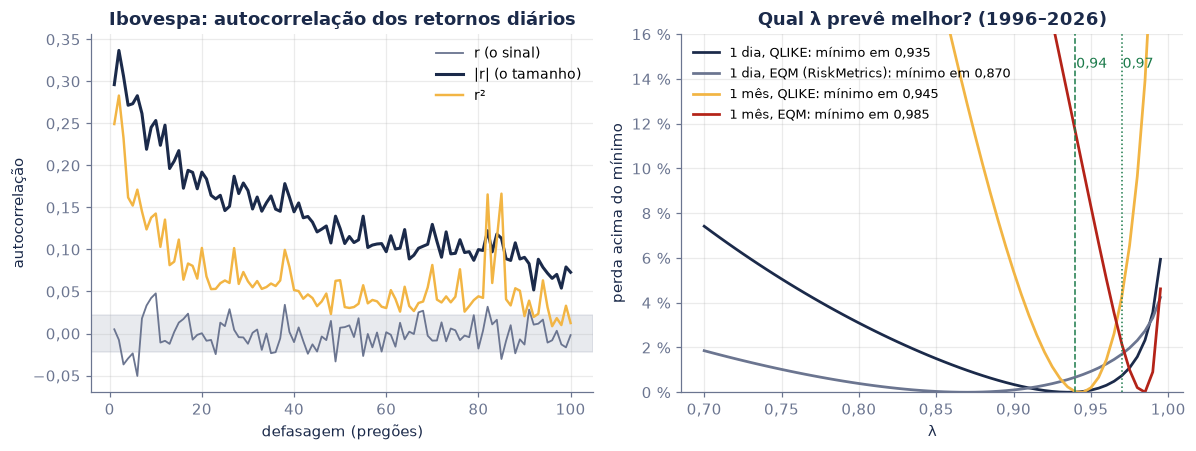

In [14]:
lams = np.round(np.arange(0.70, 0.9951, 0.005), 3)
EW = {l: ewma_var(r2, l, s0) for l in lams}
datas = r_ib.index
def melhor(a, b):
    m1 = np.zeros(len(x), bool); m1[W0:] = True; m1 &= (datas >= a) & (datas <= f"{b}-12-31")
    m21 = (datas[ts] >= a) & (datas[ts] <= f"{b}-12-31")
    rmse1 = np.array([np.sqrt(np.mean((r2[m1] - EW[l][:-1][m1]) ** 2)) for l in lams])
    ql1 = np.array([np.mean(r2[m1] / EW[l][:-1][m1] - np.log(r2[m1] / EW[l][:-1][m1] + 1e-300) - 1) for l in lams])
    eqm21 = np.array([np.mean((H * EW[l][ts + 1][m21] - rv[m21]) ** 2) for l in lams])
    ql21 = np.array([np.mean(rv[m21] / (H * EW[l][ts + 1][m21]) - np.log(rv[m21] / (H * EW[l][ts + 1][m21])) - 1) for l in lams])
    i94 = list(lams).index(0.94)
    return {"período": f"{a}–{b}", "1 dia: λ pelo EQM": lams[rmse1.argmin()], "custo de usar 0,94": rmse1[i94] / rmse1.min() - 1,
            "1 dia: λ pela QLIKE": lams[ql1.argmin()], "1 mês: λ pelo EQM": lams[eqm21.argmin()], "1 mês: λ pela QLIKE": lams[ql21.argmin()]}, (rmse1, ql1, eqm21, ql21)
res = [melhor(a, b) for a, b in (("1996", "2026"), ("1996", "2005"), ("2006", "2015"), ("2016", "2026"))]
display(pd.DataFrame([r_[0] for r_ in res]).style.format({"custo de usar 0,94": lambda v: "+" + pc(v, 2), **{c: (lambda v: br(v, 3)) for c in ("1 dia: λ pelo EQM", "1 dia: λ pela QLIKE", "1 mês: λ pelo EQM", "1 mês: λ pela QLIKE")}}).hide(axis="index"))
curvas = res[0][1]
assert [res[0][0][k] for k in ("1 dia: λ pelo EQM", "1 dia: λ pela QLIKE", "1 mês: λ pelo EQM", "1 mês: λ pela QLIKE")] == [0.87, 0.935, 0.985, 0.945]

# sem os dias extremos: quanto o ótimo do EQM depende deles?
for k_ in (1, 3, 5):
    m1 = np.zeros(len(x), bool); m1[W0:] = True; m1[np.argsort(r2)[-k_:]] = False
    l_ = lams[np.argmin([np.sqrt(np.mean((r2[m1] - EW[l][:-1][m1]) ** 2)) for l in lams])]
    print(f"1 dia, EQM, sem os {k_} maiores dias: λ = {br(l_, 3)}")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.2))
a1.plot(lags, acf["r"], color=GREY, lw=1.2, label="r (o sinal)")
a1.plot(lags, acf["|r|"], color=NAVY, lw=2, label="|r| (o tamanho)")
a1.plot(lags, acf["r²"], color=AMBER, lw=1.6, label="r²")
a1.axhspan(-2 / math.sqrt(len(x)), 2 / math.sqrt(len(x)), color=GREY, alpha=0.15)
a1.yaxis.set_major_formatter(FuncFormatter(lambda v, _: br(v, 2)))
a1.set(title="Ibovespa: autocorrelação dos retornos diários", xlabel="defasagem (pregões)", ylabel="autocorrelação"); a1.legend(frameon=False, fontsize=9)
for y, cor, nome in ((curvas[1], NAVY, "1 dia, QLIKE"), (curvas[0], GREY, "1 dia, EQM (RiskMetrics)"), (curvas[3], AMBER, "1 mês, QLIKE"), (curvas[2], RED, "1 mês, EQM")):
    a2.plot(lams, y / y.min() - 1, color=cor, lw=1.8, label=f"{nome}: mínimo em {br(lams[y.argmin()], 3)}")
a2.axvline(0.94, color=GREEN, ls="--", lw=1); a2.axvline(0.97, color=GREEN, ls=":", lw=1)
a2.text(0.9405, 0.145, "0,94", color=GREEN, fontsize=9); a2.text(0.9705, 0.145, "0,97", color=GREEN, fontsize=9)
a2.yaxis.set_major_formatter(eixo_pc(0)); a2.set_ylim(0, 0.16); a2.xaxis.set_major_formatter(FuncFormatter(lambda v, _: br(v, 2)))
a2.set(title="Qual λ prevê melhor? (1996–2026)", xlabel="λ", ylabel="perda acima do mínimo"); a2.legend(frameon=False, fontsize=8.5)
plt.tight_layout(); plt.show()

**Leitura.**

1. **A vol se agrupa; o sinal, não.** A autocorrelação de $r$ fica dentro da faixa do ruído ($\pm 0{,}023$) na maioria dos lags; a de $|r|$ é 0,296 no lag 1 e ainda 0,102 três meses depois.
2. **A replicação, pelo EQM.** Para a variância do mês seguinte, a EWMA com $\lambda = 0{,}97$ é a melhor (EQM 17 % abaixo da média longa), e a com $\lambda = 0{,}94$ empata com a janela de 252 pregões. A janela de 21 pregões é **pior que a média longa**: ela reage a tudo e esquece rápido demais. Mas os intervalos do bootstrap em blocos são largos (EWMA 0,94 contra a janela de 252: de −26 % a +31 %): o EQM é decidido por meia dúzia de crises.
3. **Pela QLIKE**, que não deixa um dia extremo mandar em tudo, a EWMA 0,94 é a melhor das seis, e a vantagem sobre a janela de 252 é significativa (intervalo de −0,211 a −0,033).
4. **O λ = 0,94 é o melhor no Brasil?** Pela QLIKE no horizonte de 1 dia, sim: o ótimo é 0,935 no período todo e fica entre 0,925 e 0,940 nos três subperíodos. Pelo EQM, o critério do documento, o ótimo é 0,87, mas a curva é plana (usar 0,94 custa 0,67 % de erro) e instável: sem o dia 15/01/1999 ele vira 0,90; em 2016–2026, por causa de março de 2020, cai para o limite da grade, 0,70. No horizonte de um mês, o EQM prefere 0,985, na linha dos 0,97 que o RiskMetrics recomenda para esse prazo.

O resultado do documento sobrevive no Brasil 30 anos depois, com uma ressalva que ele mesmo não destacava: o ótimo do erro quadrático é refém dos dias extremos.

## 8. Para o investidor: 38 ações, o CDI e o dólar

A vol serve para **comparar** investimentos, o primeiro uso que o vídeo cita. Abaixo, a vol anual pela (2) de 38 ações do Ibovespa com histórico completo desde 2015 (`dados/acoes_b3.csv`, fechamento ajustado do Yahoo Finance, de 02/01/2015 a 09/10/2026), do próprio índice no mesmo período, do dólar PTAX e do CDI.

38 ações, 2015–2026: a mais calma TAEE11 (21,9 %), a mais agitada MGLU3 (67,1 %); mediana 35,1 %; média 37,9 %
Ibovespa no mesmo período: 23,3 %  |  dólar PTAX: 14,5 %  |  CDI: 0,24 %
ações com vol menor que a do índice: 1 de 38


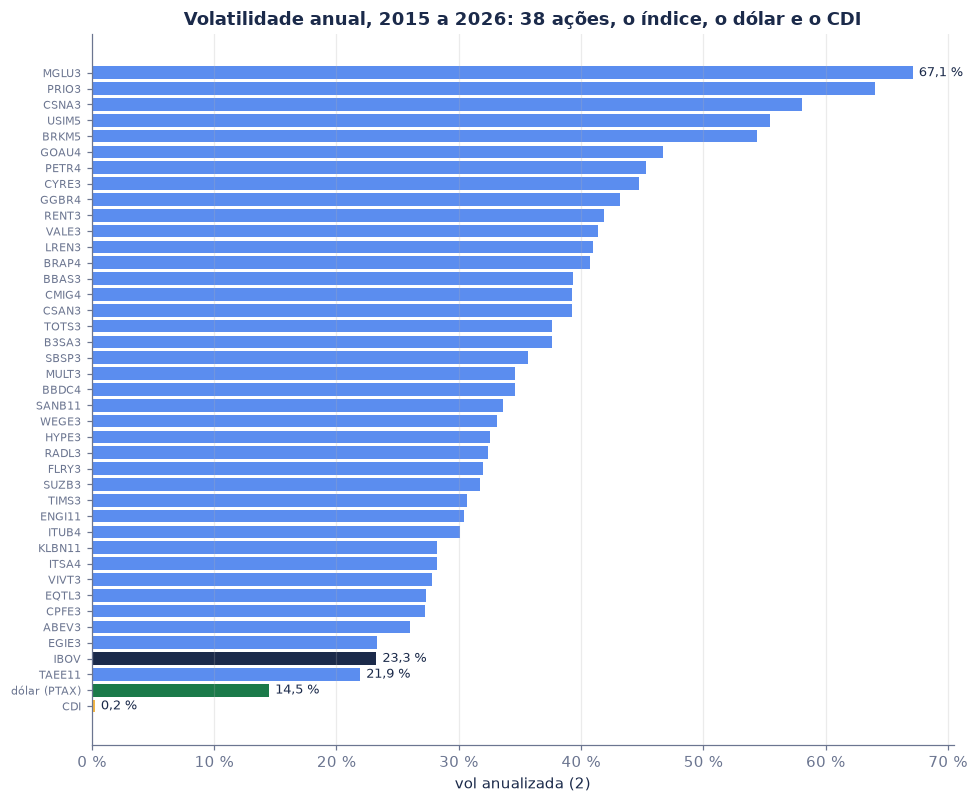

In [15]:
px = pd.read_csv("dados/acoes_b3.csv", index_col=0, parse_dates=True)
ra_ac = np.log(px).diff().dropna()
vol_ac = (ra_ac.std() * math.sqrt(252)).sort_values()
acoes = vol_ac.drop("IBOV")
cdi = pd.read_csv("dados/cdi_diario.csv", parse_dates=["data"]).set_index("data")["cdi_pct_ad"] / 100
ptax = pd.read_csv("dados/ptax.csv", parse_dates=["data"]).set_index("data")["ptax_venda"]
per = slice("2015-01-02", "2026-10-09")
vol_cdi = np.log1p(cdi[per]).std() * math.sqrt(252)
vol_usd = np.log(ptax[per]).diff().std() * math.sqrt(252)
print(f"38 ações, 2015–2026: a mais calma {acoes.index[0]} ({pc(acoes.iloc[0])}), a mais agitada {acoes.index[-1]} ({pc(acoes.iloc[-1])}); mediana {pc(acoes.median())}; média {pc(acoes.mean())}")
print(f"Ibovespa no mesmo período: {pc(vol_ac['IBOV'])}  |  dólar PTAX: {pc(vol_usd)}  |  CDI: {pc(vol_cdi, 2)}")
print(f"ações com vol menor que a do índice: {int((acoes < vol_ac['IBOV']).sum())} de {len(acoes)}")
assert len(acoes) == 38 and acoes.index[0] == "TAEE11" and acoes.index[-1] == "MGLU3" and int((acoes < vol_ac["IBOV"]).sum()) == 1

fig, ax = plt.subplots(figsize=(9, 7.4))
nomes = list(acoes.index) + ["IBOV", "dólar (PTAX)", "CDI"]
vals = list(acoes.values) + [vol_ac["IBOV"], vol_usd, vol_cdi]
ordem = np.argsort(vals)
cores = {"IBOV": NAVY, "dólar (PTAX)": GREEN, "CDI": AMBER}
ax.barh([nomes[i] for i in ordem], [vals[i] for i in ordem], color=[cores.get(nomes[i], LIGHT) for i in ordem])
for j, i in enumerate(ordem):
    if nomes[i] in cores or j in (2, len(ordem) - 1):
        ax.text(vals[i] + 0.005, j, pc(vals[i]), va="center", fontsize=8.5, color=NAVY)
ax.xaxis.set_major_formatter(eixo_pc(0)); ax.tick_params(axis="y", labelsize=7.5); ax.grid(axis="y", alpha=0)
ax.set(title="Volatilidade anual, 2015 a 2026: 38 ações, o índice, o dólar e o CDI", xlabel="vol anualizada (2)"); plt.tight_layout(); plt.show()

**Leitura.** De 2015 a 2026, a ação mais calma das 38 foi TAEE11 (transmissão de energia, receita regulada: 21,9 % ao ano) e a mais agitada, MGLU3 (67,1 %), três vezes mais. A ação mediana teve 35,1 %. O Ibovespa, com 23,3 %, foi mais calmo que **37 das 38**: a vol de uma carteira não é a média das vols, porque as ações não sobem e caem todas juntas. O dólar teve 14,5 %, e o CDI, 0,24 %.

### 8.1 O ano ruim "1 em 6"

Se o retorno do ano fosse normal, cairia abaixo de **média − 1 desvio** em 15,9 % dos anos, um ano a cada seis. É a régua mais simples para ler a vol de um fundo: "num ano ruim, mas não raro, eu perco mais ou menos a média menos a vol". Na versão lognormal da (5), o ano "1 em 6" é $e^{m - \sigma} - 1$, com $m$ a média do log. Abaixo, a régua contra a história de 1995 a 2025 (o 5º pior de 31 anos é o ano "1 em 6" observado), para quem pôs R\$ 100 mil no início de cada ano.

In [16]:
ano_cdi = (1 + cdi).groupby(cdi.index.year).prod() - 1
ano_usd = ptax.groupby(ptax.index.year).last().pct_change()
ano_usd.iloc[0] = ptax[ptax.index.year == 1995].iloc[-1] / ptax.iloc[0] - 1
print(f"CDI: maior ano {ano_cdi.idxmax()} ({pc(ano_cdi.max())}), menor ano {ano_cdi.loc[:2025].idxmin()} ({pc(ano_cdi.loc[:2025].min())})")
linhas = []
for nome, s in (("CDI", ano_cdi), ("dólar (PTAX)", ano_usd), ("Ibovespa", anos_ib["retorno"])):
    s = s.loc[1995:2025]
    l_ = np.log1p(s)
    lognorm = math.expm1(l_.mean() - l_.std())
    linhas.append({"ativo": nome, "retorno médio": s.mean(), "desvio anual": s.std(), "média − desvio": s.mean() - s.std(), "lognormal e^(m−σ) − 1": lognorm,
                   "5º pior ano (observado)": s.sort_values().iloc[4], "pior ano": s.min(), "ano do pior": str(int(s.idxmin())), "anos de perda": int((s < 0).sum()),
                   "R$ 100 mil num ano 1 em 6": 1e5 * lognorm})
t81 = pd.DataFrame(linhas)
display(t81.style.format({**{c: fpc(1) for c in ("retorno médio", "desvio anual", "média − desvio", "lognormal e^(m−σ) − 1", "5º pior ano (observado)", "pior ano")}, "R$ 100 mil num ano 1 em 6": lambda v: brl(v)}).hide(axis="index"))

CDI: maior ano 1995 (53,1 %), menor ano 2020 (2,8 %)


ativo,retorno médio,desvio anual,média − desvio,lognormal e^(m−σ) − 1,5º pior ano (observado),pior ano,ano do pior,anos de perda,R$ 100 mil num ano 1 em 6
CDI,"15,3 %","9,6 %","5,8 %","6,4 %","8,1 %","2,8 %",2020,0,R$ 6.416
dólar (PTAX),"7,9 %","19,9 %","−11,9 %","−11,3 %","−11,8 %","−25,5 %",2009,11,−R$ 11.340
Ibovespa,"18,1 %","40,4 %","−22,3 %","−17,9 %","−15,5 %","−41,2 %",2008,12,−R$ 17.888


**Leitura.** No Ibovespa, a régua normal (média − desvio = −22,3 %) exagera o ano ruim; a lognormal (−17,9 %) chega mais perto do ano "1 em 6" observado (−15,5 %). Para quem tinha R\$ 100 mil, um ano ruim mas não raro custa uns R\$ 18 mil. O pior ano, 2008 (−41,2 %), foi bem além: a vol mede o balanço típico, não o tamanho do pior ano. No dólar, as duas réguas acertam (−11,9 % e −11,3 % contra −11,8 % observado).

O CDI é o caso que ensina o que a vol **não** é: o retorno dele varia muito de um ano para outro (desvio de 9,6 %, de 53 % em 1995 a 2,8 % em 2020), mas ele nunca perdeu dinheiro e a vol diária é de 0,24 % ao ano. No começo de cada ano você já sabe mais ou menos quanto ele vai render. Variação previsível não é risco.

## 9. Na mesa: o P&L de um desvio e a vol-alvo — eq. (8)

Na mesa, a vol vira dinheiro. Com uma posição de valor $V$ e vol diária $\sigma_{\text{dia}}$, **um desvio de P&L** num dia é $V\sigma_{\text{dia}}$. E para que a posição tenha uma vol anual de $\sigma^\ast$, o tamanho é a vol-alvo dividida pela vol prevista:

$$
\text{P\&L de 1 desvio} = V\,\sigma_{\text{dia}}, \qquad w_t = \frac{\sigma^\ast}{\hat\sigma_t} \tag{8}
$$

Exemplo: **R\$ 1 milhão em BOVA11** (o ETF que replica o Ibovespa), com a vol prevista pela EWMA no fim de 16/10/2026.

In [17]:
V = 1e6
s_dia = vol_ew.iloc[-1] / math.sqrt(252)
print(f"vol EWMA no fim de 16/10/2026: {pc(vol_ew.iloc[-1])} ao ano = {pc(s_dia, 2)} ao dia")
print(f"  no fim de 02/10/2026 era {pc(vol_ew['2026-10-02'])}; o pregão de 05/10/2026 ({pc(math.expm1(r_ib['2026-10-05']))}) a levou para {pc(vol_ew['2026-10-05'])}")
print(f"P&L de 1 desvio (8): {brl(V * s_dia)} por dia  |  com a vol longa de {pc(vol_d * math.sqrt(252))}: {brl(V * vol_d)}")

# com que frequência o Ibovespa andou mais que k desvios previstos? (retorno ÷ vol EWMA do dia, sabida na véspera)
z = x[W0:] / np.sqrt(ew[W0:-1])
for k_, normal in ((1, 0.3173), (2, 0.0455), (3, 0.0027), (4, 6.3e-5)):
    print(f"|retorno| > {k_} desvio(s) previsto(s): {pc((np.abs(z) > k_).mean(), 2):>7} dos dias  |  normal: {pc(normal, 3 if normal < 0.01 else 2):>7}  |  {br((np.abs(z) > k_).mean() / normal, 1)} vezes")
print(f"desvio de retorno ÷ vol prevista: {br(z.std(), 3)} (1 se a previsão for calibrada)")
q05 = float(np.quantile(z, 0.05))
print(f"VaR de 1 dia, 95 %: normal 1,645 × {brl(V * s_dia)} = {brl(1.645 * V * s_dia)}  |  histórico filtrado ({br(-q05, 3)} desvios) = {brl(-q05 * V * s_dia)}")
q01 = float(np.quantile(z, 0.01))
print(f"VaR de 1 dia, 99 %: normal 2,326 desvios = {brl(2.326 * V * s_dia)}  |  histórico filtrado ({br(-q01, 3)} desvios) = {brl(-q01 * V * s_dia)}")

alvo = 0.10
w = alvo / vol_ew.iloc[-1]
print(f"\nvol-alvo de 10 %: {pc(w)} em BOVA11 = {brl(V * w)}; o resto, {brl(V * (1 - w))}, no CDI")
assert round(V * s_dia) == 17280 and round(V * w) == 364550

vol EWMA no fim de 16/10/2026: 27,4 % ao ano = 1,73 % ao dia
  no fim de 02/10/2026 era 17,2 %; o pregão de 05/10/2026 (7,7 %) a levou para 33,3 %
P&L de 1 desvio (8): R$ 17.280 por dia  |  com a vol longa de 31,1 %: R$ 19.598
|retorno| > 1 desvio(s) previsto(s): 30,66 % dos dias  |  normal: 31,73 %  |  1,0 vezes
|retorno| > 2 desvio(s) previsto(s):  5,55 % dos dias  |  normal:  4,55 %  |  1,2 vezes
|retorno| > 3 desvio(s) previsto(s):  0,92 % dos dias  |  normal: 0,270 %  |  3,4 vezes
|retorno| > 4 desvio(s) previsto(s):  0,28 % dos dias  |  normal: 0,006 %  |  43,7 vezes
desvio de retorno ÷ vol prevista: 1,046 (1 se a previsão for calibrada)
VaR de 1 dia, 95 %: normal 1,645 × R$ 17.280 = R$ 28.426  |  histórico filtrado (1,702 desvios) = R$ 29.418
VaR de 1 dia, 99 %: normal 2,326 desvios = R$ 40.193  |  histórico filtrado (2,608 desvios) = R$ 45.065

vol-alvo de 10 %: 36,5 % em BOVA11 = R$ 364.550; o resto, R$ 635.450, no CDI


vol anual de cada ano, 1996–2026: Ibovespa de 12,9 % a 57,6 %  |  vol-alvo de 9,6 % a 11,6 %
desvio médio da vol de cada ano até 10 %: Ibovespa 17,8 %  |  vol-alvo 0,5 %
peso médio no Ibovespa: 45 %; dias no limite de 150 %: 0,0 %
retorno anual composto: Ibovespa 13,6 % | vol-alvo 14,3 % | CDI 14,2 %
maior queda do topo: Ibovespa −65,0 % | vol-alvo −19,2 %
Sharpe sobre o CDI: Ibovespa 0,13 | vol-alvo 0,07


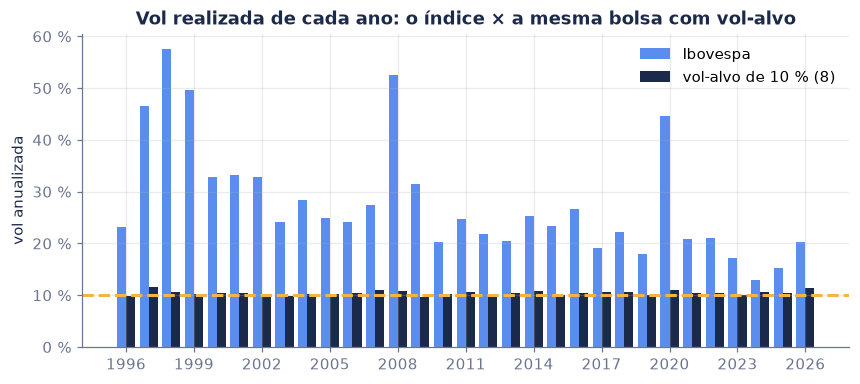

In [18]:
# vol-alvo de 10 % desde 1996: peso no Ibovespa decidido na véspera pela EWMA, limitado a 150 %; o resto no CDI
ret_ib = np.expm1(r_ib)
idx_cdi = (1 + cdi).cumprod().shift(1).fillna(1.0)
ret_cdi = idx_cdi.reindex(ibov.index, method="ffill").pct_change().reindex(r_ib.index).fillna(0.0)
peso = (alvo / pd.Series(np.sqrt(252 * ew[:-1]), index=r_ib.index)).clip(upper=1.5)
cart = (peso * ret_ib + (1 - peso) * ret_cdi)["1996":]
ib96 = ret_ib["1996":]
vol_cart = cart.groupby(cart.index.year).std() * math.sqrt(252)
vol_ib = ib96.groupby(ib96.index.year).std() * math.sqrt(252)
print(f"vol anual de cada ano, 1996–2026: Ibovespa de {pc(vol_ib.min())} a {pc(vol_ib.max())}  |  vol-alvo de {pc(vol_cart.min())} a {pc(vol_cart.max())}")
print(f"desvio médio da vol de cada ano até 10 %: Ibovespa {pc((vol_ib - alvo).abs().mean())}  |  vol-alvo {pc((vol_cart - alvo).abs().mean())}")
print(f"peso médio no Ibovespa: {pc(peso['1996':].mean(), 0)}; dias no limite de 150 %: {pc((peso['1996':] >= 1.5).mean())}")
dd = lambda r_: float((np.cumprod(1 + r_) / np.maximum.accumulate(np.cumprod(1 + r_)) - 1).min())
anos_n = len(cart) / 252
print(f"retorno anual composto: Ibovespa {pc(np.prod(1 + ib96) ** (1 / anos_n) - 1)} | vol-alvo {pc(np.prod(1 + cart) ** (1 / anos_n) - 1)} | CDI {pc(np.prod(1 + ret_cdi['1996':]) ** (1 / anos_n) - 1)}")
print(f"maior queda do topo: Ibovespa {pc(dd(ib96.values))} | vol-alvo {pc(dd(cart.values))}")
cdi96 = ret_cdi["1996":]
sharpe = lambda r_: float((r_ - cdi96).mean() / (r_ - cdi96).std() * math.sqrt(252))
print(f"Sharpe sobre o CDI: Ibovespa {br(sharpe(ib96), 2)} | vol-alvo {br(sharpe(cart), 2)}")

fig, ax = plt.subplots(figsize=(9, 3.7))
xs = np.arange(len(vol_ib))
ax.bar(xs - 0.2, vol_ib.values, width=0.4, color=LIGHT, label="Ibovespa")
ax.bar(xs + 0.2, vol_cart.values, width=0.4, color=NAVY, label="vol-alvo de 10 % (8)")
ax.axhline(alvo, color=AMBER, lw=2, ls="--")
ax.set_xticks(xs[::3]); ax.set_xticklabels(vol_ib.index[::3])
ax.yaxis.set_major_formatter(eixo_pc(0))
ax.set(title="Vol realizada de cada ano: o índice × a mesma bolsa com vol-alvo", ylabel="vol anualizada"); ax.legend(frameon=False); plt.show()

**Leitura.** Com a vol prevista de 27,4 % no fim de 16/10/2026, R\$ 1 milhão em BOVA11 tem um desvio de P&L de **R\$ 17.280 por dia**. Boa parte disso é um dia só: em 02/10/2026 a vol EWMA era 17,2 %; o pregão de 05/10/2026, o primeiro depois do 1º turno das eleições (+7,7 %), a levou para 33,3 %, e ela vem caindo desde então. É a EWMA fazendo o que promete: reagir rápido e esquecer devagar.

A previsão é calibrada no meio da distribuição (o retorno passou de 1 desvio previsto em 30,7 % dos dias, contra 31,7 % na normal), mas não nas caudas: passou de 3 desvios em 0,92 % dos dias (3,4 vezes a normal) e de 4 desvios em 0,28 % (umas 44 vezes). Para limite de perda, a vol é o começo da conta, não o fim.

A vol-alvo faz o que promete: de 1996 a 2026, a vol de cada ano ficou entre 9,6 % e 11,6 %, contra 12,9 % a 57,6 % do índice, e a maior queda do topo caiu de −65,0 % para −19,2 %. **Resultado ruim também vai ao ar:** o retorno não melhorou de verdade. A carteira rendeu 14,3 % ao ano, contra 14,2 % do CDI e 13,6 % do Ibovespa: nesses 30 anos, a bolsa brasileira não pagou prêmio sobre o CDI, e controlar a vol não cria um prêmio que não existe. A vol-alvo só "ganhou" do índice no retorno composto porque sofreu menos arrasto (seção 4). Pelo índice de Sharpe sobre o CDI (média do excesso diário ÷ desvio, anualizado), ela até piorou: 0,07 contra 0,13 do Ibovespa. Em ações americanas, Moreira e Muir (2017) acham ganho de Sharpe com regras desse tipo; aqui, de 1996 a 2026, não aparece.

## 10. O que a volatilidade não vê

1. **A direção.** A vol é simétrica: um dia de +5 % e um de −5 % pesam igual. Ela mede o balanço, não se o balanço é a favor. As seções 4 e 5 mostram que a média é que decide o destino, e que a média quase não dá para medir.
2. **As caudas.** A regra "2 em 3" e a (5) supõem a curva de sino. No Ibovespa, dias de mais de 4 desvios previstos acontecem dezenas de vezes mais que na normal. Para a perda extrema, a ferramenta é o VaR e o *expected shortfall*, não a vol.
3. **Que ela muda.** Um número só para 31 anos esconde 1998, 2008 e 2020. A vol de ontem é uma previsão, e a seção 7 mostra que nenhuma regra simples prevê o choque.
4. **O que não tem preço todo dia.** Um fundo de crédito marcado na curva, um imóvel, uma empresa fechada: preço que não muda não tem vol, mas tem risco. A vol baixa pode ser só falta de preço.
5. **A dependência entre ativos.** A vol de uma carteira não é a média das vols: depende das correlações. Por isso o Ibovespa é mais calmo que quase todas as 38 ações dele.

### Para praticar (respostas na célula seguinte)

1. Uma ação tem desvio diário de 1,5 %. Qual a vol anual pela (2)? E a vol semanal?
2. Um fundo promete 10 % ao ano em média, com vol de 20 %. Pela (5), qual a chance de um ano de perda? E pela conta ingênua?
3. Com retornos normais, quantos pregões são precisos para conhecer a vol com ±5 % (95 % de confiança)?
4. Na EWMA com $\lambda = 0{,}94$, qual a meia-vida do peso de um retorno? E quanto do peso total está nos últimos 21 pregões?
5. Uma mesa tem R\$ 5 milhões em BOVA11 e vol prevista de 25 % ao ano. Qual o P&L de 1 desvio por dia? Para vol-alvo de 10 %, quanto deveria estar em BOVA11?

In [19]:
print("1)", f"1,5 % × √252 = {pc(0.015 * math.sqrt(252))} ao ano;  1,5 % × √5 = {pc(0.015 * math.sqrt(5), 2)} por semana")
print("2)", f"(5): Φ(−(ln 1,10 − 0,2²/2)/0,2) = {pc(p_perda(0.20, mu_a=0.10))};  ingênua Φ(−0,10/0,20) = {pc(Phi(-0.5))}")
print("3)", f"(6) com κ = 3: n ≥ 1,96² × 2/(4 × 0,05²) = {br(1.96 ** 2 * 2 / (4 * 0.05 ** 2), 0)} pregões (uns 3 anos)")
print("4)", f"meia-vida ln 0,5/ln 0,94 = {br(math.log(0.5) / math.log(0.94), 1)} pregões;  peso dos últimos 21: 1 − 0,94^21 = {pc(1 - 0.94 ** 21)}")
print("5)", f"5 mi × 25 %/√252 = {brl(5e6 * 0.25 / math.sqrt(252))} por dia;  vol-alvo: 5 mi × 10/25 = {brl(5e6 * 0.10 / 0.25)} em BOVA11")

1) 1,5 % × √252 = 23,8 % ao ano;  1,5 % × √5 = 3,35 % por semana
2) (5): Φ(−(ln 1,10 − 0,2²/2)/0,2) = 35,3 %;  ingênua Φ(−0,10/0,20) = 30,9 %
3) (6) com κ = 3: n ≥ 1,96² × 2/(4 × 0,05²) = 768 pregões (uns 3 anos)
4) meia-vida ln 0,5/ln 0,94 = 11,2 pregões;  peso dos últimos 21: 1 − 0,94^21 = 72,7 %
5) 5 mi × 25 %/√252 = R$ 78.743 por dia;  vol-alvo: 5 mi × 10/25 = R$ 2.000.000 em BOVA11


---

### Resumo de fórmulas

| | Fórmula | Neste notebook |
|---|---|---|
| (1) Desvio-padrão | $\sigma = \sqrt{\frac1n\sum (r_i - \bar r)^2}$ | 0,25 % e 1,99 % ao dia |
| (2) Regra da raiz quadrada | $\sigma_{\text{ano}} = \sigma_{\text{dia}}\sqrt{252}$ | × 15,87: 3,9 % e 31,6 % ao ano |
| (3) Com autocorrelação | $\mathrm{Var}(\sum r_i) = n\sigma^2[1 + 2\sum(1-\frac kn)\rho_k]$ | razão de variâncias do Ibovespa |
| (4) Curva de sino | $P(\mu-\sigma < X < \mu+\sigma) = 68{,}3\,\%$ | 64,1 % e 65,8 % na simulação |
| (5) Ano de perda | $\Phi\big(-(\ln(1+\mu_a) - \sigma^2/2)/\sigma\big)$ | 2,7 % e 46,8 % |
| (6) Erro da vol estimada | $\mathrm{EP}(\hat\sigma)/\sigma \approx \sqrt{(\kappa-1)/(4n)}$ | 192 pregões para ±10 % |
| (7) EWMA | $\sigma^2_{t+1} = \lambda\sigma^2_t + (1-\lambda)r_t^2$ | RiskMetrics: λ = 0,94 |
| (8) Mesa | $V\sigma_{\text{dia}}$ e $w = \sigma^\ast/\hat\sigma$ | BOVA11 e vol-alvo de 10 % |

### Referências

- Bollerslev, T. (1986). Generalized autoregressive conditional heteroskedasticity. *Journal of Econometrics*, 31(3), 307–327.
- Engle, R. F. (1982). Autoregressive conditional heteroscedasticity with estimates of the variance of United Kingdom inflation. *Econometrica*, 50(4), 987–1007.
- J.P. Morgan/Reuters (1996). *RiskMetrics — Technical Document*, 4ª ed. New York: Morgan Guaranty Trust Company.
- Lo, A. W.; MacKinlay, A. C. (1988). Stock market prices do not follow random walks: evidence from a simple specification test. *Review of Financial Studies*, 1(1), 41–66.
- Mandelbrot, B. (1963). The variation of certain speculative prices. *Journal of Business*, 36(4), 394–419.
- Merton, R. C. (1980). On estimating the expected return on the market: an exploratory investigation. *Journal of Financial Economics*, 8(4), 323–361.
- Moreira, A.; Muir, T. (2017). Volatility-managed portfolios. *Journal of Finance*, 72(4), 1611–1644.
- Patton, A. J. (2011). Volatility forecast comparison using imperfect volatility proxies. *Journal of Econometrics*, 160(1), 246–256.
- Dados: Yahoo Finance (`^BVSP` e ações, fechamento ajustado); Banco Central do Brasil, SGS, séries 12 (CDI) e 1 (dólar PTAX de venda).

---

<sub>Gabriel Pires · [gabrielppires.com](https://gabrielppires.com) · [@gabrielp.piress](https://instagram.com/gabrielp.piress). O vídeo é inspirado em *Quant Finance from Scratch*, de [@quantfinancetogo](https://instagram.com/quantfinancetogo). Simulação nas seções 0 a 5; dados reais do Ibovespa, de 38 ações, do CDI e do dólar nas seções 6 a 9. Só educação, não é recomendação de investimento.</sub>